<>:143: SyntaxWarning: invalid escape sequence '\P'
<>:320: SyntaxWarning: invalid escape sequence '\m'
<>:321: SyntaxWarning: invalid escape sequence '\m'
<>:334: SyntaxWarning: invalid escape sequence '\m'
<>:335: SyntaxWarning: invalid escape sequence '\m'
<>:968: SyntaxWarning: invalid escape sequence '\p'
<>:992: SyntaxWarning: invalid escape sequence '\p'
<>:1014: SyntaxWarning: invalid escape sequence '\p'
<>:1121: SyntaxWarning: invalid escape sequence '\P'
<>:1179: SyntaxWarning: invalid escape sequence '\P'
<>:1213: SyntaxWarning: invalid escape sequence '\P'
<>:2850: SyntaxWarning: invalid escape sequence '\m'
<>:2928: SyntaxWarning: invalid escape sequence '\m'
<>:2942: SyntaxWarning: invalid escape sequence '\m'
<>:3025: SyntaxWarning: invalid escape sequence '\A'
<>:3066: SyntaxWarning: invalid escape sequence '\m'
<>:143: SyntaxWarning: invalid escape sequence '\P'
<>:320: SyntaxWarning: invalid escape sequence '\m'
<>:321: SyntaxWarning: invalid escape sequence '\m'
<>:

Your matrix <\Psi_i|\partial H /\partial Q|\Psi_j> file:inpfile/VPpy0108_all_p.out
Your master matrix file:TPsv1/py0817_all_pt_sig10
The T_list is:
[ 2  3  4  5  6  7  8  9 10 12 14 15 16 18 20 25 30 35 40 45 50]
point 1

There are  201 frequency analysis in the log file, and we always use the first part.
When this number is greater than 1, the first part contains more digit numbers for the 
displacement vectors. 



c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\gen_structures.py:111: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vecs = np.empty([n_freq_analysis,self.orig.get_number_of_atoms(),3], dtype = float)
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\gen_structures.py:124: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for j in range(0,self.orig.get_number_of_atoms()):
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\gen_structures.py:131: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for j in range(0,self.orig.get_number_of_atoms()):
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\gen_structures.py:158: FutureWarning: Please use le

finish reading CFPs
finish reading CFPs
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200]
check the TO
Add magnetic field: 0.01 T
Work on Orbach TPs of T = 2K
Work on Raman TPs of T = 2K
Work on Orbach TPs of T = 3K
Work on Raman TPs

c:\Users\10122\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\10122\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
C:\Users\10122\AppData\Local\Temp\ipykernel_23120\1970841499.py:3091: ComplexWarning: Casting complex values to real discards the imaginary part
  print(Mlabel+"U_{eff} of Orbach is "+'%1.1f'%OBimfor[0]+" K")
C:\Users\10122\AppData\Local\Temp\ipykernel_23120\1970841499.py:3092: ComplexWarning: Casting complex values to real discards the imaginary part
  print("log(tau) is "+'%1.2f'%logOBtau+" s")


TestU_{eff} of Orbach is 57.6 K
log(tau) is -7.48 s


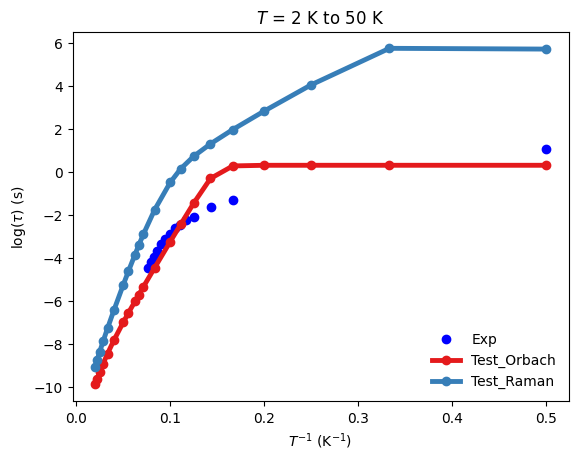

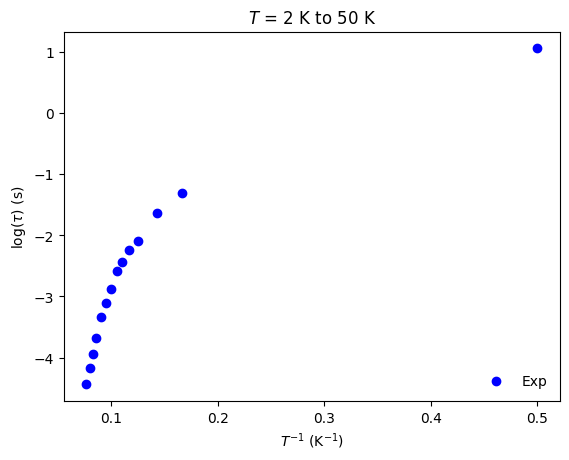

In [1]:
#!/usr/bin/env python3
# -*- coding:utf-8 -*-

import importlib
import random
import numpy as np
from numpy import polyfit, poly1d
import argparse
from pathlib import Path
import shutil 
import os 
import sys
import re
import yaml
import gen_structures
importlib.reload(gen_structures)
from Select_group import choose_group
from gen_structures import mol_freq
from prettytable import PrettyTable
import scipy
from scipy.optimize import curve_fit
from scipy.linalg import eig, eigh
from scipy.sparse.linalg import eigs, eigsh

import warnings # 忽略SyntaxWarning类型的警告
warnings.filterwarnings("ignore", category=SyntaxWarning)

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.pyplot import MultipleLocator
from matplotlib import cycler
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from ase import Atoms
from ase.io import read
from ase.visualize import view
from ase.build import fcc111, add_adsorbate
from ase.io import write
from ase.io import vasp

symbols = {
    1: "H",    2: "He",    
    3: "Li",    4: "Be",    5: "B",    6: "C",    7: "N",    8: "O",    9: "F",    10: "Ne",    
    11: "Na",    12: "Mg",    13: "Al",    14: "Si",    15: "P",    16: "S",    17: "Cl",    18: "Ar",    
    19: "K",    20: "Ca",    21: "Sc",    22: "Ti",    23: "V",    24: "Cr",    25: "Mn",    26: "Fe",    27: "Co",    28: "Ni",    29: "Cu",    30: "Zn",    31: "Ga",    32: "Ge",    33: "As",    34: "Se",    35: "Br",    36: "Kr",
    37: "Rb",    38: "Sr",    39: "Y",    40: "Zr",    41: "Nb",    42: "Mo",    43: "Tc",    44: "Ru",    45: "Rh",    46: "Pd",    47: "Ag",    48: "Cd",    49: "In",    50: "Sn",    51: "Sb",    52: "Te",    53: "I",    54: "Xe",    
    55: "Cs",   56: "Ba",    
    57: "La",    58: "Ce",    59: "Pr",    60: "Nd",    61: "Pm",    62: "Sm",    63: "Eu",    64: "Gd",    65: "Tb",    66: "Dy",    67: "Ho",    68: "Er",    69: "Tm",    70: "Yb",    
    71: "Lu",    72: "Hf",    73: "Ta",    74: "W",    75: "Re",    76: "Os",    77: "Ir",    78: "Pt",    79: "Au",    80: "Hg",    81: "Tl",    82: "Pb",    83: "Bi",    84: "Po",    
    85: "At",    86: "Rn",
}


element_dict = {
    "H": 1,    "He": 2,    
    "Li": 3,    "Be": 4,    "B": 5,    "C": 6,    "N": 7,    "O": 8,    "F": 9,    "Ne": 10,    
    "Na": 11,    "Mg": 12,    "Al": 13,    "Si": 14,    "P": 15,    "S": 16,    "Cl": 17,    "Ar": 18,    
    "K": 19,    "Ca": 20,    "Sc": 21,    "Ti": 22,    "V": 23,    "Cr": 24,    "Mn": 25,    "Fe": 26,    "Co": 27,    "Ni": 28,    "Cu": 29,    "Zn": 30,    "Ga": 31,    "Ge": 32,    "As": 33,    "Se": 34,    "Br": 35,    "Kr": 36,
    "Rb": 37,    "Sr": 38,    "Y": 39,    "Zr": 40,    "Nb": 41,    "Mo": 42,    "Tc": 43,    "Ru": 44,    "Rh": 45,    "Pd": 46,    "Ag": 47,    "Cd": 48,    "In": 49,    "Sn": 50,    "Sb": 51,    "Te": 52,    "I": 53,    "Xe": 54,    
    "Cs": 55,    "Ba": 56,    
    "La": 57,    "Ce": 58,    "Pr": 59,    "Nd": 60,    "Pm": 61,    "Sm": 62,    "Eu": 63,    "Gd": 64,    "Tb": 65,    "Dy": 66,    "Ho": 67,    "Er": 68,    "Tm": 69,    "Yb": 70,    
    "Lu": 71,    "Hf": 72,    "Ta": 73,    "W": 74,    "Re": 75,    "Os": 76,    "Ir": 77,    "Pt": 78,    "Au": 79,    "Hg": 80,    "Tl": 81,    "Pb": 82,    "Bi": 83,   
}


atMass = {
    'H': 1.008,    'He': 4.003,    
    'Li': 6.941,    'Be': 9.012,    'B': 10.81,     'C': 12.01,    'N': 14.01,    'O': 16.00,     'F': 19.00,     'Ne': 20.18,     
    'Na': 22.99,    'Mg': 24.31,    'Al': 26.98,    'Si': 28.09,    'P': 30.97,    'S': 32.07,    'Cl': 35.45,    'Ar': 39.95,    
    'K': 39.10, 'Ca': 40.08,    'Sc': 44.96,    'Ti': 47.87,    'V': 50.94,    'Cr': 52.00,    'Mn': 54.94,    'Fe': 55.85,    'Ni': 58.69,    'Co': 58.93,    'Cu': 63.55,    'Zn': 65.38,    'Ga': 69.72,    'Ge': 72.63,    'As': 74.92,    'Se': 78.96,    'Br': 79.90,    'Kr': 83.80,
    'Rb': 85.47,    'Sr': 87.62,    'Y': 88.91,    'Zr': 91.22,    'Nb': 92.91,    'Mo': 95.94,    'Tc': 98.00,    'Ru': 101.07,    'Rh': 102.91,    'Pd': 106.42,    'Ag': 107.87,    'Cd': 112.41,    'In': 114.82,    'Sn': 118.71,    'Sb': 121.76,    'I': 126.90,    'Te': 127.60,    'Xe': 131.29,
    'Cs': 132.91,    'Ba': 137.33,
    'La': 138.91,    'Ce': 140.12,    'Pr': 140.91,    'Nd': 144.24,    'Pm': 145.00,    'Sm': 150.36,    'Eu': 151.96,    'Gd': 157.25,    'Tb': 158.93,    'Dy': 162.50,    'Ho': 164.93,    'Er': 167.26,    'Tm': 168.93,    'Yb': 173.05,
    'Lu': 174.97,    'Hf': 178.49,    'Ta': 180.95,    'W': 183.84,    'Re': 186.21,    'Os': 190.23,    'Ir': 192.22,    'Pt': 195.08,    'Au': 196.97,    'Hg': 200.59,    'Tl': 204.38,    'Pb': 207.2,    'Bi': 208.98,
}
palette = plt.get_cmap('Set1')


#设置常量类
class _const:
    class ConstError(TypeError):pass
    def __setattr__(self,name,value):
        if name in self.__dict__:
            raise self.ConstError("Can't rebind const (%s)" %name)
        self.__dict__[name]=value
        
const = _const()

##################################### constants ####################################
# conversion factor from m (reduced mass, amu) and w (frequency, cm^-1) to the amplitude of a harmonic oscillator x ( Angstrom)
const.hbar = 1.05457266
const.amu = 1.66053886
const.c = 2.9979
const.kb = 13.80649
x_fac = np.sqrt( const.hbar / (const.amu * 2.0 * np.pi * const.c) ) * 10 ** 1.5
#    x = x_fac / np.sqrt( m * w)

# checking
# print("x_fac = ", x_fac)


#设置清屏函数
def is_in_notebook():
    import sys
    return 'ipykernel' in sys.modules

def clear_output():
    """
    clear output for both jupyter notebook and the console
    """
    import os
    os.system('cls' if os.name == 'nt' else 'clear')
    if is_in_notebook():
        from IPython.display import clear_output as clear
        clear()

class CAL_RELAX(object):
    def __init__(self, Input_filename):
        #self.Inpfile = Input_filename
        with open(Input_filename,"r") as file:
            finput = file.read()
        pinput = yaml.safe_load(finput)
        self.pinput = pinput

    def kernel(self):
        self.Read_input()
        self.Read_freq()
        self.Read_CFPs()
        self.Read_Static_effH()
        self.Analyse_Relax()


    def Read_input(self):
        pinput = self.pinput
        self.CFPs_filename = pinput['CFPs_filename']
        self.mag_filename = pinput['mag_filename']
        self.freq_filename = pinput['freq_filename']
        self.POSCAR = pinput['POSCAR']
        self.TPs_foldname = pinput['TPs_foldname']
        self.TO_foldname = pinput['TO_foldname']
        self.VP_filename = pinput['VP_filename']
        print('Your matrix <\Psi_i|\partial H /\partial Q|\Psi_j> file:'+self.VP_filename)
        print('Your master matrix file:'+self.TPs_foldname)
        self.Out_foldname = pinput['Out_foldname']
        self.CFPs_X = pinput['CFPs_X']
        self.Correction_slope = float(pinput['Correction_slope'])    #Correction_slope of freq
        self.Corrected_intercept = float(pinput['Corrected_intercept'])    #Corrected_intercept of freq
        self.Fitting_order = int(pinput['Fitting_order'])
        self.sigma = float(pinput['Linewidth_parameter']) #Linewidth_parameter
        self.If_Data = bool(pinput['If_Data'])
        self.If_Perb = bool(pinput['If_Perb'])
        self.Perb_T = float(pinput['Perb_T'])
        self.If_uniformization = bool(pinput['If_uniformization'])
        self.CFPs_Type = int(pinput['CFPs_Type'])
        self.Ab_Type = int(pinput['Ab_Type'])
        self.If_get_picture_Tt = bool(pinput['If_get_picture_Tt'])
        self.If_select_sigma = bool(pinput['If_select_sigma'])
        self.If_Orbach = bool(pinput['If_Orbach'])
        self.If_Raman = bool(pinput['If_Raman'])
        self.If_Simplified = bool(pinput['If_Simplified'])
        self.If_Full = bool(pinput['If_Full'])
        if not Path(self.Out_foldname).is_dir():
            os.makedirs(self.Out_foldname)
        """
        Generate the T_list
        """
        self.T_list = gen_T_list(pinput)

    def Read_freq(self):
        """
        Read freq
        """
        self.mol = mol_freq(self.freq_filename,self.POSCAR)
        print("point 1")
        self.mol.read_geometry()
        #view(mol.orig)
        self.mol.read_modes_vasp()
        self.mol.gen_massvecs_m()
        self.mol.freqs = self.Correction_slope*self.mol.freqs+self.Corrected_intercept

    def Read_CFPs(self):
        """
        Read CFPs
        """

        self.CFPs = CFPs_Analyze(self.CFPs_filename,self.CFPs_X)
        self.CFPs.info(self.mol.freqs.size)
        """CFPs type:
        0:normal mode CFPs
        1:xyz mode CFPs
        2:xyz+reduce mode CFPs
        3:Lorentz random CFPs
        """
        match self.CFPs_Type:
            case 0:
                self.CFPs.propare_CFPs(self.mol,CFPs_Type=self.CFPs_Type)
            case 1:
                self.CFPs.propare_CFPs(self.mol,CFPs_Type=self.CFPs_Type)
            case 2:
                molfile = self.pinput['Molfile']
                try:
                    ct_idx = self.pinput['ct_idx']
                except:
                    ct_idx='Dy'
                try:
                    Atom_radius = float(self.pinput['Atom_radius'])
                    self.CFPs.propare_CFPs(self.mol,CFPs_Type=self.CFPs_Type,radius=Atom_radius,molfile=molfile,ct_idx=ct_idx)
                except:
                    Atom_label = float(self.pinput['Atom_label'])
                    self.CFPs.propare_CFPs(self.mol,CFPs_Type=self.CFPs_Type,Atom_label=Atom_label,molfile=molfile,ct_idx=ct_idx)
            case 3:
                llzA = float(self.pinput['llzA'])
                llzw = float(self.pinput['llzw'])
                self.CFPs.propare_CFPs(self.mol,CFPs_Type=self.CFPs_Type,llzA=llzA,llzw=llzw)

        print("finish reading CFPs")
        
        if self.If_select_sigma:
            self.select_sigma = self.pinput['select_sigma']
        self.Modes_list = np.linspace(0,self.CFPs.nmds-1,num = self.CFPs.nmds,dtype = int)
        print(self.Modes_list)
    
    def Read_Static_effH(self):
        """
        Read energy and wavefunction
        """
        self.Eigen = Eigenstates(self.mag_filename)
        """Ab type:
        0:Molcas
        1:Openmocas
        2:Orca
        3:Pyscf
        """
        match self.Ab_Type:
            case 0:
                self.Eigen.read_energies_M()
                self.Eigen.read_wavefunction_M()
            case 1:
                self.Eigen.read_energies_OM()
                self.Eigen.read_wavefunction_OM()
            case 3:
                self.Eigen.read_energies_Pyscf()
                self.Eigen.read_wavefunction_Pyscf()
        self.Eigen.gen_J_number()
        self.Eigen.propare_TO(self.TO_foldname)
        if self.If_Perb:
            self.Eigen.Pertubation(self.Perb_T) 

    def SPC_Analyse(self):
        """
        SPC analyse
        """
        CarHs_atom(self.CFPs)
        SPC_atom(self.CFPs)
        
        density_spc(self.CFPs,self.mol,2000,"SPC_2k.png")
        density_spc_3D(self.CFPs,self.mol,1600,3.8,"dSPCdr")
        #density_spc(CFPs,mol,2000,"SPC_2k.png")
        #clear_output()
        return True
    
    def Analyse_Relax(self):
        T_list = self.T_list
        pinput= self.pinput
        if self.If_get_picture_Tt and self.If_Data:        
            """
            Draw the data you pre-entered in .yml
            """
            ndata = int(pinput['ndata'])
            for i in range(1,ndata+1):
                Tr = pinput['Tr{x}'.format(x = i)]
                logtime = pinput['logtime{x}'.format(x = i)]
                lb = pinput['label{x}'.format(x = i)]
                fig1.plot(Tr,logtime,"ob",label=lb)
                fig2.plot(Tr,logtime,"ob",label=lb)

        AllOBRate_list = []
        AllOBRate_list2 = []
        AllRMRate_list = []
        AllRMRate_list2 = []
        AllRMRate_list_lt = []
        AllTTRate_list = []
        TPlist_rds = np.empty((0,),dtype = float)

        Mlabel=self.Calculate_relax()
        TPlabel = 0
        self.TP = []
        for T in self.T_list:
            #Calculate_T(T,Modes_list,TPs_foldname)
            #self.name = 'TP{x}'.format(x=TPlabel)
            #print(locals()[self.name])
            self.TP.append(self.Calculate_T(T))
            

        if self.If_uniformization:
            draw_uni(TPlist_rds,T_list,Mlabel,self.Out_foldname,If_pic=self.If_get_picture_Tt)


        AllOBRate_list.append(np.array(Y(TPs_Analyze.OBRate_list)))
        AllOBRate_list2.append(np.array(Y(TPs_Analyze.OBRate_list2)))
        AllRMRate_list.append(np.array(Y(TPs_Analyze.RMRate_list)))
        AllRMRate_list2.append(np.array(Y(TPs_Analyze.RMRate_list2)))
        AllRMRate_list_lt.append(np.array(Y(TPs_Analyze.RMRate_list_lt)))
        AllTTRate_list.append(np.array(Y(TPs_Analyze.Rate_list)))
        Refresh_TPs()

        if self.If_Orbach:
            plt.figure("Fig1")
            drwa_OB(Mlabel, AllOBRate_list,T_list,self.Out_foldname+"/OB_v1.dat",If_pic=self.If_get_picture_Tt)
            
        if self.If_Raman:
            plt.figure("Fig1")
            drwa_RM(Mlabel, AllRMRate_list,T_list,self.Out_foldname+"/RM_v1.dat",color=1,If_pic=self.If_get_picture_Tt)

        plt.figure("Fig1")
        plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
        Tmin = T_list[0]
        Tmax = np.max(T_list)
        fig1.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
        fig1.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
        fig1.set_ylabel(r"log($\mathit{\tau}$) (s)") 
        #fig1.set_xlim(0.005,0.02)
        fig1.yaxis.set_major_locator(MultipleLocator(2))
        #fig1.set_ylim(-6,4)
        #fig1.xaxis.set_major_locator(MultipleLocator(0.01))
        #plt.xticks(1/T_list,T_list)   
        plt.savefig("TPs1.png",bbox_inches='tight')

        plt.figure("Fig2")
        plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
        Tmin = T_list[0]
        Tmax = np.max(T_list)
        fig2.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
        fig2.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
        fig2.set_ylabel(r"log($\mathit{\tau}$) (s)") 
        #fig2.set_xlim(0.005,0.02)
        #fig2.set_ylim(-4,4)
        plt.savefig("TPs2.png",bbox_inches='tight')

        plt.show()

    def Calculate_relax(self):
        pinput = self.pinput
        If_Orbach = bool(pinput['If_Orbach'])
        If_Raman = bool(pinput['If_Raman'])
        Mlabel = 'Test'
        nloop=1
        Eigen = self.Eigen
        CFPs = self.CFPs
        mol = self.CFPs
        VP_filename = self.VP_filename
        TPs_foldname = self.TPs_foldname
        Modes_list = self.Modes_list
        for k in range(0,nloop):
            """if Cal_idx == 1:
                #CFPs.random_CFPs_gs(Simsigma)
                CFPs.random_CFPs_llz(llzA,llzw)
                VP_filename = SimVP_filename+"llz{x}_{y}.log".format(x = llzA,y = Sim_idx)
                TPs_foldname = SimTPs_foldname+"llz{x}_{y}".format(x = llzA,y = Sim_idx)"""

            if Path(VP_filename).is_file():
                Eigen.read_sph_matrix(VP_filename)
            else:
                print("There is no corresponding .vp file, get the perturbation potential matrix  ")
                Eigen.gen_sph_matrix(VP_filename,Modes_list,CFPs,self.If_select_sigma,self.select_sigma)        
            if not Path(TPs_foldname).is_dir():
                os.makedirs(TPs_foldname)
            for T in self.T_list:
                T = int(T)
                if If_Orbach:
                    print("Work on Orbach TPs of T = {x}K".format(x=T))
                    TPs_filename1 = TPs_foldname+"/OB{x}.tps".format(x = T)
                    if Path(TPs_filename1).is_file():
                        self.check_select_sigma(TPs_filename1)
                    else:
                        self.gen_OBTPs(T,TPs_filename1)
                #"""    
                if If_Raman:
                    TPs_filename2 = TPs_foldname+"/LM{x}.tps".format(x = T)
                    print("Work on Raman TPs of T = {x}K".format(x=T))
                    if Path(TPs_filename2).is_file():
                        self.check_select_sigma(TPs_filename2)
                    else:
                        self.gen_RMTPs(T,TPs_filename2)

            return Mlabel

    def Calculate_T(self,T):
        #name = 'TP{x}_{y}'.format(x=T,y=k)
        TP_temp = TPs_Analyze(T,self.Modes_list,self)
        if self.If_Orbach:
            TPs_filename1 = self.TPs_foldname+"/OB{x}.tps".format(x = T)
            TP_temp.read_OBTPs(TPs_filename1)
            TP_filename = self.TPs_foldname+"/OB{x}.tp".format(x=T)
            np.savetxt(TP_filename,TP_temp.OBTP)
        #"""    
        if self.If_Raman:
            TPs_filename2 = self.TPs_foldname+"/LM{x}.tps".format(x = T)
            TP_temp.read_RMTPs(TPs_filename2)
            TP_filename = self.TPs_foldname+"/LM{x}.tp".format(x=T)
            np.savetxt(TP_filename,TP_temp.RMTP)  
        TP_temp.sum_OBRMTPs()
        if self.If_uniformization:
            print("Simulation TPs of T = {x}K".format(x=T))
            TP_temp.uniformization()
            TPlist_rds = np.append(TPlist_rds,-TP_temp.TP[0,0])
        return TP_temp

    def check_select_sigma(self,TPs_filename):
        with open(TPs_filename,'r') as file:
            line = file.readline()
            line = file.readline()
            line = file.readline()
            line = file.readline()
        if line.split()[1] == "True":
            if not self.If_select_sigma:
                print("the .tps file use select_sigma, but the .yml file didn't use ")
                sys.exit(0)
            if self.select_sigma < float(line.split()[3]):
                print("your select_sigma is less than the one when calculate the {x}, but it is OK read it.".format(x = TPs_filename))
            if self.select_sigma > float(line.split()[3]):
                print("your select_sigma is bigger than the one when calculate the {x}, please delete this file and run this program again.".format(x = TPs_filename))
                sys.exit(0)

    def gen_RMTPs(self,T,TPs_filename,select_sigma = 1000):
        """
        Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
        """
        CFPs = self.CFPs
        Eigen = self.Eigen
        mol = self.mol
        Modes_list = self.Modes_list
        print("Calculate the Raman TPs of T = {x}K".format(x=T))
        TP_nmds = Modes_list.shape[0]
        TP = np.zeros([Eigen.n_states,Eigen.n_states,CFPs.nmds,CFPs.nmds], dtype = float)
        with open(TPs_filename+".dat","w") as file:    
            file.write("The Transparant Probilities\n")
            file.write("Total modes {x}\n".format(x=CFPs.nmds))
            file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
            file.write("If_select_sigma: {x} ".format(x=self.If_select_sigma))
            if self.If_select_sigma:
                file.write("select_sigma: {x}\n".format(x=self.select_sigma))
            else:
                file.write("\n")
            TPcount = 0
            TPtest = 0
            for j in Modes_list:
                for k in Modes_list:
                    if j <= k:
                        continue
                    file.write("modes {x} modes {y}\n".format(x=j+1,y=k+1))
                    for f in range(0,Eigen.n_states):
                        for i in range(0,Eigen.n_states):
                            omega_fi = Eigen.Vaules[f]-Eigen.Vaules[i]
                            if abs(omega_fi) < -10 and j != k: #abs(omega_fi) > 10 or
                                #print(omega_fi)
                                TP[f,i,j,k] = 0
                            else:
                                omega1 = mol.freqs[j]
                                omega2 = mol.freqs[k]
                                a = 0
                                b11=0
                                b12 = 0
                                c = 0
                                d21=0
                                d22 = 0
                                if abs(omega_fi+omega1+omega2) < select_sigma:
                                    a = get_RM_VP(Eigen,f,i,j,k,omega1,omega2)
                                    b11 = a*green_RM11(omega_fi,omega1,omega2,self.sigma,T)
                                if abs(omega_fi-omega1+omega2) < select_sigma:
                                    a = get_RM_VP(Eigen,f,i,j,k,-omega1,omega2)
                                    b12 = a*green_RM12(omega_fi,omega1,omega2,self.sigma,T)
                                if abs(omega_fi+omega1-omega2) < select_sigma:
                                    c = get_RM_VP(Eigen,f,i,j,k,omega1,-omega2)
                                    d21 = c*green_RM21(omega_fi,omega1,omega2,self.sigma,T)
                                if abs(omega_fi-omega1-omega2) < select_sigma:
                                    c = get_RM_VP(Eigen,f,i,j,k,-omega1,-omega2)
                                    d22 = c*green_RM22(omega_fi,omega1,omega2,self.sigma,T)
                                """b11 = get_RM_VP(Eigen,f,i,j,k,omega2)*green_RM11(omega_fi,omega1,omega2,sigma,T)
                                b12 = get_RM_VP(Eigen,f,i,j,k,omega2)*green_RM12(omega_fi,omega1,omega2,sigma,T)
                                d21 = get_RM_VP(Eigen,f,i,j,k,-omega2)*green_RM21(omega_fi,omega1,omega2,sigma,T)
                                d22 = get_RM_VP(Eigen,f,i,j,k,-omega2)*green_RM22(omega_fi,omega1,omega2,sigma,T)"""
                                TP[f,i,j,k] =np.pi**2*const.c*1e10*(b11+b12+d21+d22)*(1-Delta(f,i))/4
                        file.write(" ".join(str(s) for s in TP[f,...,j,k])+"\n")
        os.rename(TPs_filename+".dat",TPs_filename)
        TPs = np.zeros([Eigen.n_states,Eigen.n_states], dtype = float)
        for j in range(0,CFPs.nmds):
            for k in range(0,CFPs.nmds):
                TPs += TP[...,j,k]
        for i in range(0,Eigen.n_states):
            for j in range(0,Eigen.n_states):
                if i != j:
                    TPs[i,i] -= TPs[j,i]
        return TPs

    def gen_OBTPs(self,T,TPs_filename):
        """
        Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
        """
        CFPs = self.CFPs
        Eigen = self.Eigen
        mol = self.mol
        Modes_list = self.Modes_list
        print("Calculate the Orbach TPs of T = {x}K".format(x=T))
        TP_nmds = Modes_list.shape[0]
        TP = np.zeros([Eigen.n_states,Eigen.n_states,CFPs.nmds], dtype = float)
        with open(TPs_filename+".dat","w") as file:    
            file.write("The Transparant Probilities\n")
            file.write("Total modes {x}\n".format(x=CFPs.nmds))
            file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
            file.write("If_select_sigma: {x} ".format(x=self.If_select_sigma))
            if self.If_select_sigma:
                file.write("select_sigma: {x}\n".format(x=self.select_sigma))
            else:
                file.write("\n")
            for j in Modes_list:
                file.write("modes {x}\n".format(x=j+1))
                for f in range(0,Eigen.n_states):
                    for i in range(0,Eigen.n_states):
                        omega_fi = Eigen.Vaules[f]-Eigen.Vaules[i]
                        a = get_Mod_square(Eigen.VP[f,i,j])
                        omega1 = mol.freqs[j]
                        b = green_OB(omega_fi,omega1,self.sigma,T)
                        #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
                        #c = Rou_omega(abs(omega_if),omega1,sigma)
                        TP[f,i,j] =2*np.pi**2*a*b*const.c*1e10*(1-Delta(f,i))
                        if T == 80 and f == 3 and i == 0 and TP[3,0,j]>1e4:
                            print("modes:{x}".format(x=j))
                            d22 = a*b
                            a1 = np.exp(-0.5*((omega_fi-omega1)/self.sigma)**2)/(self.sigma*np.sqrt(2.0*np.pi))
                            a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                            b1 = np.exp(-0.5*((omega_fi+omega1)/self.sigma)**2)/(self.sigma*np.sqrt(2.0*np.pi))
                            b2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                            gre = a1*a2+b1*b2
                            print("a:",'%1.2e'%a,"d22:",'%1.2e'%d22,"green:",'%1.2e'%b)
                            print("a1:",'%1.2e'%a1,"a2:",'%1.2e'%a2,"b1:",'%1.2e'%b1,"b2:",'%1.2e'%b2)
                    file.write(" ".join(str(s) for s in TP[f,...,j])+"\n")
        os.rename(TPs_filename+".dat",TPs_filename)
        TPs = np.zeros([Eigen.n_states,Eigen.n_states], dtype = float)
        for j in range(0,CFPs.nmds):
            TPs += TP[...,j]
        for i in range(0,Eigen.n_states):
            for j in range(0,Eigen.n_states):
                if i != j:
                    TPs[i,i] -= TPs[j,i]
        return TPs

class CFPs_Analyze(object):
    """
        the object corresponds to analyze the CFPs.
    """ 
    def __init__(self, filename,CFPs_X):
        self.filename = filename
        self.X = CFPs_X
    
    def read_CFPs(self):
        """
        read CFPs, number of modes, and the number of points from the file filename 
        """
        with open(self.filename,"r") as file:
            line = file.readline()
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            npts = int(line.split()[2])
            B = np.empty([nmds,npts,27], dtype = float)
            B2 = np.empty([5], dtype = float)   #B_kq,where k = 2
            B4 = np.empty([9], dtype = float)   #B_kq,where k = 4
            B6 = np.empty([13], dtype = float)  #B_kq,where k = 6
            for i in range(0,nmds):
                #print("work on mode "+str(i+1))
                for j in range(0,npts):
                    line = file.readline()
                    i = int(line.split()[1])-1
                    line = file.readline()
                    B2 = line.split()
                    B[i,j,0:5] = B2
                    line = file.readline()
                    B4 = line.split()
                    B[i,j,5:14] = B4
                    line = file.readline()
                    B6 = line.split()
                    B[i,j,14:27] = B6    
        B = np.insert(B,(npts+1)//2,0,axis = 1) #add the eq perturbation CFPs
        self.nmdsori = nmds
        self.npts = npts
        self.Bkq = B

    def read_CFPs_xyz(self):
        """
        read CFPs, number of modes, and the number of points from the file filename 
        """
        with open(self.filename,"r") as file:
            line = file.readline()
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            npts = int(line.split()[2])
            B = np.empty([nmds,npts,27], dtype = float)
            B2 = np.empty([5], dtype = float)   #B_kq,where k = 2
            B4 = np.empty([9], dtype = float)   #B_kq,where k = 4
            B6 = np.empty([13], dtype = float)  #B_kq,where k = 6
            for i in range(0,nmds):
                #print("work on mode "+str(i+1))
                for j in range(0,npts):
                    line = file.readline()
                    i = int(line.split()[1])-1
                    line = file.readline()
                    B2 = line.split()
                    B[i,j,0:5] = B2
                    line = file.readline()
                    B4 = line.split()
                    B[i,j,5:14] = B4
                    line = file.readline()
                    B6 = line.split()
                    B[i,j,14:27] = B6    
        B = np.insert(B,(npts+1)//2,0,axis = 1) #add the eq perturbation CFPs
        self.xyznmd = nmds
        self.npts = npts
        self.Bkq = B

    def read_gtensors(self,gfile):
        """
        read CFPs, number of modes, and the number of points from the file filename 
        """
        with open(gfile,"r") as file:
            line = file.readline()
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            npts = int(line.split()[2])

            line = file.readline()
            line = file.readline()
            self.eqgz = float(line.split()[0])
            line = file.readline()
            self.eqgax = np.asarray(line.split(), dtype = float)

            gtensor = np.empty([nmds,npts], dtype = float)
            gaxis = np.empty([nmds,npts,3], dtype = float)
            dgvec = np.zeros([nmds,npts,3], dtype = float)
            dgtheta = np.empty([nmds,npts], dtype = float)
            dgz = np.empty([nmds,npts], dtype = float)
            for i in range(0,nmds):
                #print("work on mode "+str(i+1))
                for j in range(0,npts):
                    line = file.readline()
                    line = file.readline()
                    gz = line.split()
                    gtensor[i,j] = gz[0]
                    line = file.readline()
                    axis = line.split()
                    #print(axis)
                    gaxis[i,j,0:3] = axis   
                    if gaxis[i,j,2] == 0:
                        #print("not")
                        dgtheta[i,j] = 0
                        dgz[i,j] = 0
                    else:
                        #print(self.eqgax,gaxis[i,j,...])
                        theta = calculate_angle_between_lines(self.eqgax,gaxis[i,j,...])
                        dgtheta[i,j] = theta
                        dgzv = self.eqgz - float(gz[0])
                        dgz[i,j] = dgzv
                        dgvec[i,j,0] = gtensor[i,j]*gaxis[i,j,0]-self.eqgz*self.eqgax[0]
                        dgvec[i,j,1] = gtensor[i,j]*gaxis[i,j,1]-self.eqgz*self.eqgax[1]
                        dgvec[i,j,2] = gtensor[i,j]*gaxis[i,j,2]-self.eqgz*self.eqgax[2]
            dgtheta = np.insert(dgtheta,(npts+1)//2,0,axis = 1) #add the eq perturbation CFPs
            dgz = np.insert(dgz,(npts+1)//2,0,axis = 1) #add the eq perturbation CFPs
            dgvec = np.insert(dgvec,(npts+1)//2,0,axis = 1)
        self.gaxis = gaxis
        self.gtensor = gtensor
        self.dgtheta = dgtheta
        self.dgz = dgz
        self.dgvec = dgvec

    def propare_CFPs(self,mol,CFPs_Type=0,atoms_label=None,radius=0,dradius=0.001,molfile=None,outfold='./',ct_idx='Dy',llzA=0,llzw=0):
        """CFPs label:
        0:normal mode CFPs
        1:xyz mode CFPs
        2:xyz+reduce mode CFPs
        3:Lorentz random CFPs
        """
        match CFPs_Type:
            case 0:
                self.read_CFPs()
                self.gen_slope()
            case 1:
                self.read_CFPs_xyz()
                self.gen_slope_xyz()
                self.transB_sl(mol.massvecs)
            case 2:
                if radius != 0:
                    origgr,newgr,atoms_label=choose_group(molfile,ct_idx,outfold,radius,dradius)
                self.gen_slope_reduced(atoms_label)
                self.transB_sl(mol.massvecs)
            case 3:
                if llzw !=0 and llzA != 0:
                    self.random_CFPs_llz(llzA,llzw)
                else:
                    print("ERROR!!!!!! Please input llzA and llzw")

        print("finish reading CFPs")

    def info(self,nmds,npts=None):
        """
        change the information: number of modes, and the number of points
        """
        self.nmds = nmds
        if npts!=None:
            self.npts = npts

    def lierror_CFPs(self,x):
        """
        Apply a linear error to B_kq, the value of error is (1-x,1+x)
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        for i in range(0,self.nmds):
            for k in range(0,27):
                a = random.uniform(1-x,1+x)
                B_slope[i,k] = self.B_slope[i,k]*a
        self.B_slope = B_slope
        
    def random_CFPs_mod(self,x):
        """
        generate the random B_kq by choose the random mode
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        Mod = np.empty([int(x)], dtype = int)
        for i in range(0,int(x)):
            Mod[i] = random.randint(0,self.nmds-1)
        for i in range(0,self.nmds):
            for k in range(0,27):
                j = random.randint(0,9)
                B_slope[i,k] = self.B_slope[Mod[j],k]
        self.B_slope = B_slope

    def random_CFPs_llz(self,llzA,llzw):
        """
        generate the random B_kq by a gaussan distribution
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        #print(llzA,llzw)
        rdmllz = generate_sim_lorentz(llzA,llzw,27)
        for i in range(0,self.nmds):
            for k in range(0,5):
                B_slope[i,k] = rdmllz[k]*theta_2
            for k in range(5,14):
                B_slope[i,k] = rdmllz[k]*theta_4
            for k in range(14,27):
                B_slope[i,k] = rdmllz[k]*theta_6
        self.B_slope = B_slope 

    def Line_CFPs(self):
        """
        Put the B_slope in a 1D array
        """
        B = np.empty((0,),dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B = np.append(B,self.B_slope[i,k]/theta_2)
            for k in range(5,14):
                B = np.append(B,self.B_slope[i,k]/theta_4)
            for k in range(14,27):
                B = np.append(B,self.B_slope[i,k]/theta_6)
        return B

    def write_CFPs(self,filename):
        """
        write CFPs, number of modes, and the number of points from the file filename  
        """
        B = self.Bkq
        with open(filename,"w") as file:
            file.write("The Perturbation CFPs\n")
            file.write("Total modes {x}\n".format(x=self.nmds))
            file.write("Total points {y}\n".format(y=self.npts))
            for imod in range(0,self.nmds):
                for ipt in range(0,5):
                    print("Working on the Mode {x} Point {y}".format(x=imod+1,y=ipt+1))
                    file.write("Mode {x} Point {y}\n".format(x=imod+1,y=ipt+1))
                    B2 = B[imod,ipt,0:5]
                    B4 = B[imod,ipt,5:14]
                    B6 = B[imod,ipt,14:27]
                    file.write(" ".join(str(s) for s in B2)+"\n")
                    file.write(" ".join(str(s) for s in B4)+"\n")
                    file.write(" ".join(str(s) for s in B6)+"\n")
        
    def save_picture(self,foldname):
        """
        save the figture of B_kq correspond to displacement x on every vibration mode 
        """
        if not os.path.exists(foldname):
            os.makedirs(foldname)
        else:
            print("the folder foldname exists, delete it and run this program again")
            return 0
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            os.makedirs("{f}/mode{x}".format(f=foldname,x=i+1))
            for j in range(0,5):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_2,label = str(j-2))
            plt.xlim(-0.1,0.1)
            plt.ylim(-200,200)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 2)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_2.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=2")
            for j in range(5,14):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_4,label = str(j-9))
            plt.xlim(-0.1,0.1)
            plt.ylim(-200,200)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 4)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_4.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=4")
            for j in range(14,27):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_6,label = str(j-20))
            plt.xlim(-0.1,0.1)
            plt.ylim(-200,200)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 6)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_6.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=6")
            clear_output()
        return 1
    
    def gen_picture(self,n):
        """
        gen the figture of B_kq correspond to displacement x on vibration mode 'n'
        """
        clear_output()
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for j in range(0,5):
            plt.plot(self.X,self.Bkq[i,...,j]/theta_2,label = str(j-2))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 2)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=2")
        for j in range(5,14):
            plt.plot(self.X,self.Bkq[n-1,...,j]/theta_4,label = str(j-9))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 4)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=4")
        for j in range(14,27):
            plt.plot(self.X,self.Bkq[n-1,...,j]/theta_6,label = str(j-20))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 6)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=6")
    
    def gen_slope(self):
        """
        Fit the linear function of B(X) to x
        """
        B_slope = np.zeros([self.nmdsori,27], dtype = float)
        for i in range(0,self.nmds):
            X,B = self.select_XB(i)
            #print(i,X,B)
            for j in range(0,27):
                B_slope[i,j] = polyfit(X, B[...,j], 1)[0]
        self.B_slope = B_slope

    def gen_slope_xyz(self):
        """
        Fit the linear function of B(X) to x
        """
        B_slope = np.zeros([self.xyznmd,27], dtype = float)
        for i in range(0,self.xyznmd):
            X,B = self.select_XB(i)
            #print(i,X,B)
            for j in range(0,27):
                B_slope[i,j] = polyfit(X, B[...,j], 1)[0]
        self.B_slopexyz = B_slope

    def gen_slope_reduced(self,atoms_label):
            """
            Fit the function of B(X) to x wirh n-th order function and only consider the nearest atoms
            """
            print("only consider the xzymodes of the nearest atoms")
            B_slope = np.zeros([self.xyznmd,27], dtype = float)
            #atoms_label = np.array([1,2,3,4,6,7,35,36,53,62,66], dtype = int)
            for k in atoms_label:
                for l in range(3):
                    i = k*3+l
                    for j in range(0,27):
                        B_slope[i,j] = polyfit(self.X, self.Bkq[i,...,j], 1)[0]
            self.B_slopexyz = B_slope

    def gen_unmassslope(self,mol):
        
        B_slope = np.empty([self.nmds,27], dtype = float)
        for i in range(0,self.nmds):
            X,B = self.select_XB(i)
            x = x_fac / np.sqrt(mol.masses[i] * mol.freqs[i])
            #print(i,X,B)
            for j in range(0,27):
                B_slope[i,j] = polyfit(X, B[...,j], 1)[0]/x
        self.B_slope = B_slope

    def select_XB(self,i):
        X = np.empty((0,),dtype = float)
        B = np.empty(shape=[0, 27], dtype = float)
        Btest = self.Bkq[i,...]
        for k in range(0,self.npts+1):
            if Btest[k,0] != 0 or k == (self.npts+1)//2:
                #print(np.shape(B))
                #print(Btest[k,...])
                B = np.append(B, [Btest[k,...]], axis=0)
                X = np.append(X,self.X[k])
        return X,B
        
    def gen_coeff2(self,n):
        """
        Fit the function of B(X) to x wirh n-th order function, not used now
        """
        coeff = np.empty([self.nmds,27,n+1], dtype = float)
        for i in range(0,self.nmds):
            for j in range(0,27):
                X = [-0.2,-0.1,0,0.1,0.2]
                Y = [self.Bkq[i,0,j],self.Bkq[i,3,j],self.Bkq[i,5,j]]
                coeff[i,j,...] = polyfit(self.X, self.Bkq[i,...,j], n)
        self.coeff = coeff
    
    def gen_B_x(self,x,m,n):
        """
        gen B(X) to x wirh mode m and Bkq sequence n
        """
        f = poly1d(self.coeff[m-1,n,...])
        return f(x)

    def transB_sl(self,vecs):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        Select_Atnum = np.loadtxt('inpfile/Atom_list',dtype=int)
        B_slope = np.zeros([self.nmds,27],dtype = float)
        B_slope_tot = np.zeros([self.nmds,self.xyznmd,27],dtype = float)
        for i in range(self.nmds):
            for j in range(0,27):
                bstemp = 0
                for z in range(self.xyznmd):
                    z1 = int(z/3)
                    z2 = z%3
                    B_slope_tot[i,z,j] = vecs[i,Select_Atnum[z1],z2]*self.B_slopexyz[z,j]
                    bstemp = bstemp+vecs[i,Select_Atnum[z1],z2]*self.B_slopexyz[z,j]
                B_slope[i,j] = bstemp
        self.B_slope = B_slope
        self.B_slope_tot = B_slope_tot
        return B_slope
    
    def transB_sl_select(self,vecs):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        First_Atnum = np.loadtxt('inpfile/First_list',dtype=int)
        number = First_Atnum.shape[0]
        B_slope = np.empty([self.nmds,27],dtype = float)
        for i in range(self.nmds):
            for j in range(0,27):
                bstemp = 0
                for z in range(number):
                    z1 = int(z/3)
                    z2 = z%3
                    bstemp = bstemp+vecs[i,First_Atnum[z1],z2]*self.B_slopexyz[z,j]
                B_slope[i,j] = bstemp
        self.B_slope = B_slope
        return B_slope
    
    def transB_toxyz(self,mol):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        Select_Atnum = np.loadtxt('inpfile/Atom_list',dtype=int)
        num_of_at_sl = Select_Atnum.shape[0]
        hbar = 1.05457266
        amu = 1.66053886
        c = 2.9979
        x_fac = np.sqrt( hbar / (amu * 2.0 * np.pi * c) ) * 10 ** 1.5
        #num_of_at = mol.orig.get_number_of_atoms()
        mass = np.empty([3*num_of_at_sl],dtype = float)
        vecs_sl = np.empty([mol.vecs.shape[0],3*num_of_at_sl],dtype = float)
        for j in range(0,num_of_at_sl):
            mass[3*j] = atMass[symbols[mol.orig.get_atomic_numbers()[Select_Atnum[j]]]]
            mass[3*j+1] = atMass[symbols[mol.orig.get_atomic_numbers()[Select_Atnum[j]]]]
            mass[3*j+2] = atMass[symbols[mol.orig.get_atomic_numbers()[Select_Atnum[j]]]]
            vecs_sl[...,3*j] = mol.vecs[...,Select_Atnum[j],0]
            vecs_sl[...,3*j+1] = mol.vecs[...,Select_Atnum[j],1]
            vecs_sl[...,3*j+2] = mol.vecs[...,Select_Atnum[j],2]
        B_slopetr = np.empty([self.B_slope.shape[0],self.B_slope.shape[1]],dtype = float)
        for imod in range(mol.freqs.size):
            B_slopetr[imod,...] = self.B_slope[imod,...]*np.sqrt(mol.freqs[imod])
        vecs_inv = scipy.linalg.pinv(vecs_sl)
        #print(B_slopetr.shape)
        #print(vecs_inv.shape)

        B_slopexyz = np.einsum('ji, kj->ki', B_slopetr,vecs_inv)
        for imod in range(0,B_slopexyz.shape[0]):
            B_slopexyz[imod,...] = B_slopexyz[imod,...]*np.sqrt(mass[imod])/x_fac
        self.B_slopexyz = B_slopexyz
        #print(B_slopexyz)
        np.savetxt('Bslope_trxyz',B_slopexyz)
        return 1

class Eigenstates(object):
    """
        the object corresponds to analyze the Eigenstates.
    """ 
    def __init__(self, filename):
        self.filename = filename

    def read_energies_Pyscf(self):
        """
        read Energies from the file filename, get the eigenvalues list of E, and the number of eigenstates n )  
        """
        E = []   #B_kq,where k = 2
        with open(self.filename,"r", encoding="utf-8") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 6 and " ".join(line.split())== "Nj eigevanlues of the electronic H": #find the correct position
                    # find the correct position,
                    for i in range(0,5):
                        line = file.readline()
                    i = 0
                    while True:
                        line = file.readline()
                        
                        if line.split()[0] == "|":
                            #print(line.split())
                            E += [float(line.split()[3])]
                            i += 1 
                        else:
                            self.Vaules = E
                            self.n_states = i
                            J = float((self.n_states-1)/2)
                            self.J = J
                            return 1
            print("not find eigenvaules")
            return 0
    
    def read_energies_OM(self):
        """
        read Energies from the OpenMolcas file filename, get the eigenvalues list of E, and the number of eigenstates n )  
        """
        E = []   #B_kq,where k = 2
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 9 and " ".join(line.split())== "ENERGY SPLITTING INDUCED BY CUMMULATIVE INDIVIDUAL-RANK OPERATORS (in cm-1).": #find the correct position
                    # find the correct position,
                    for i in range(0,4):
                        line = file.readline()
                    i = 0
                    while True:
                        line = file.readline()
                        if line.split()[0] == "w.f.":
                            E += [float(line.split()[3])]
                            i += 1 

                        else:
                            self.Vaules = E
                            self.n_states = i
                            J = float((self.n_states-1)/2)
                            self.J = J
                            return 1
            print("not find eigenstates")
            return 0
        
    def read_wavefunction_Pyscf(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found 
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r", encoding="utf-8") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 7 and " ".join(line.split()) == "H eigenstates in the Jz eigenstates basis":
                    #for i in range(0,1):
                    line = file.readline()
                    for k in range(0,self.n_states):
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            A[k,i] = float(line.split('|')[2])
                            B[k,i] = float(line.split('|')[3])
                    C = A + B*1j  
                    np.savetxt("wavefunction_C",C)  
                    self.A = A
                    self.B = B  
            
    def read_energies_M(self):
            """
            read Energies from the Molcas file filename, get the eigenvalues list of E, and the number of eigenstates n )  
            """
            E = []   #B_kq,where k = 2
            with open(self.filename,"r") as file:
                while True:
                    line = file.readline()
                    if not line:
                        break
                    if len(line.split()) == 10 and " ".join(line.split()) == "OF THE CRYSTAL-FIELD MATRIX USING THE ABOVE PARAMETERS (in cm-1).": #find the correct position
                        # find the correct position,
                        for i in range(0,5):
                            line = file.readline()
                        i = 0
                        while True:
                            line = file.readline()
                            if line.split()[0] == "w.f.":
                                E += [float(line.split()[3])]
                                i += 1 

                            else:
                                self.Vaules = E
                                self.n_states = i
                                J = float((self.n_states-1)/2)
                                self.J = J
                                return 1
                print("not find eigenstates")
                return 0
    
    def read_wavefunction_M(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the Molcas file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 15 and " ".join(line.split()[:6]) == "DECOMPOSITION OF THE RASSI WAVE FUNCTIONS":
                    for k in range(0,self.n_states//4):
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,4):
                                a = line.split("|")[j+1]
                                A[j+4*k,i] = float(a.split()[0])
                                B[j+4*k,i] = float(a.split()[1])
                    if self.n_states%4 != 0:
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,self.n_states%4):
                                a = line.split("|")[j+1]
                                A[j+self.n_states//4,i] = float(a.split()[0])
                                B[j+self.n_states//4,i] = float(a.split()[1])
                    self.A = A
                    self.B = B   
                    
    def read_wavefunction_OM(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the OpenMolcas file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found 
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 15 and " ".join(line.split()[:6]) == "DECOMPOSITION OF THE RASSI WAVE FUNCTIONS":
                    for i in range(0,3):
                            line = file.readline()
                    for k in range(0,self.n_states//2):
                        for i in range(0,3):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            temp = pattern.findall(line.split('|')[2].split()[0])
                            A[2*k,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[2].split()[1])
                            B[2*k,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[4].split()[0])
                            A[2*k+1,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[4].split()[1])
                            B[2*k+1,i] = float(temp[0])*10**float(temp[1])
                    if self.n_states%2 != 0:
                        for i in range(0,3):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,self.n_states%2):
                                a = line.split("|")[j+1]
                                temp = pattern.findall(line.split('|')[2].split()[0])
                                A[j+self.n_states//2,i] = float(temp[0])*10**float(temp[1])
                                temp = pattern.findall(line.split('|')[2].split()[1])
                                B[j+self.n_states//2,i] = float(temp[0])*10**float(temp[1])
                    self.A = A
                    self.B = B  
    
    def extract_CFPs(self):
        """
        extract  CFPs from the file filename, return three list of B_kq, correspond to k=2,4,6)  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found
        B2 = np.empty([5], dtype = float)   #B_kq,where k = 2
        B4 = np.empty([9], dtype = float)   #B_kq,where k = 4
        B6 = np.empty([13], dtype = float)  #B_kq,where k = 6
        with open(self.filename,"r") as f:
            while True:
                line = f.readline()
                if not line:
                    break
                if len(line.split()) == 3 and " ".join(line.split()) == "The Crystal-Field Hamiltonian:": #find the correct position
                    for i in range(0,5):
                        line = f.readline()
                    if line.split()[4] =='"EasySpin"': #find the correct position
                        for i in range(0,9):
                            line = f.readline()
                        for i in range(0,5):
                            line = f.readline()
                            CFPs = pattern.findall(line.split('|')[3])
                            CFPs = float(CFPs[0])*10**float(CFPs[1])
                            B2[i] = float(CFPs)
                        line = f.readline()
                        for i in range(0,9):
                            line = f.readline()
                            CFPs = pattern.findall(line.split('|')[3])
                            CFPs = float(CFPs[0])*10**float(CFPs[1])
                            B4[i] = float(CFPs)
                        line = f.readline()
                        for i in range(0,13):
                            line = f.readline()
                            CFPs = pattern.findall(line.split('|')[3])
                            CFPs = float(CFPs[0])*10**float(CFPs[1])
                            B6[i] = float(CFPs)
                        line = f.readline()
                        break
        B_eq = np.empty([27], dtype = float)
        B_eq[0:5] = B2
        B_eq[5:14] = B4
        B_eq[14:27] = B6  
        self.B_eq = B_eq
        return B_eq

    def diag_H(self):
        """
        diag matrix <JM_1|B_{kq}O_{kq}|JM_2>  
        """
        SH = np.empty([self.n_states,self.n_states], dtype = complex)
        for i in range(0,self.n_states):
            for j in range(0,self.n_states):
                val_temp = 0
                for k in range(0,27):
                    val_temp += self.TO[i,j,k]*self.B_eq[k]
                SH[i,j] = val_temp
        self.SH = SH
        E,V = np.linalg.eig(SH)
        E,V = Sort_EV(E,V)
        for i in range(0,self.n_states):
            for j in range(0,self.n_states):
                self.A[i,j] = V[j,i].real
                self.B[i,j] = V[j,i].imag
        return E,V
    
    def propare_TO(self,TO_foldname):
        print("check the TO")
        if Path(TO_foldname+"/"+str(self.n_states)+"_real.eso").is_file() and Path(TO_foldname+"/"+str(self.n_states)+"_imag.eso").is_file():
            self.read_TO_matrix(TO_foldname)
        else:
            print("There is no corresponding .eso file, get the extend steven's operators from easyspin of matlab  ")
            self.gen_TO_matrix()

    def gen_TO_matrix(self):
        """
        generate the extend Steven's operators(TO) matrix from easyspin in matlab
        """
        import matlab.engine
        TO = np.empty([self.n_states,self.n_states,27], dtype = complex)
        J = float((self.n_states-1)/2)
        eng = matlab.engine.start_matlab()
        for i in range(0,27): 
            k = get_kq(i)[0]
            q = get_kq(i)[1]
            TO[...,i] = eng.stev(float(J),float(k),float(q))
        eng.quit()
        self.J = J
        self.TO = TO

    def gen_J_number(self):
        """
        distribute the J angular for each state
        """
        JAN = np.empty([self.n_states], dtype = float)
        for i in range(0,self.n_states):
            jantemp = 0
            for j in range(0,int(self.n_states/2)):
                jantemp += (self.A[i,j]**2+self.B[i,j]**2)*(-self.J+j)+(self.A[i,self.n_states-1-j]**2+self.B[i,self.n_states-j-1]**2)*(self.J-j)
            #print(jantemp)
            JAN[i] = jantemp
        self.JAN = JAN
        
    def gen_J_number_old(self):
        """
        distribute the J angular for each state
        """
        JAN = np.empty([self.n_states], dtype = float)
        for i in range(0,int(self.n_states/2)):
            x1 = self.A[2*i,i]**2+self.B[2*i,i]**2
            y1 = self.A[2*i,self.n_states-1-i]**2+self.B[2*i,self.n_states-i-1]**2
            #x2 = self.A[2*i+1,i]**2+self.B[2*i+1,i]**2
            #y2 = self.A[2*i+1,self.n_states-1-i]**2+self.B[2*i+1,self.n_states-i-1]**2
            if x1>y1:
                JAN[2*i] = -self.J+i
                JAN[2*i+1] = self.J-i
            else:
                JAN[2*i] = self.J-i
                JAN[2*i+1] = -self.J+i  
        self.JAN = JAN
    
    def read_TO_matrix(self,TO_foldname):
        """
        read the TO matrix from the fold "TO"
        """
        TO = np.empty([self.n_states,self.n_states,27], dtype = complex)
        A = np.empty([self.n_states,self.n_states,27], dtype = float)
        B = np.empty([self.n_states,self.n_states,27], dtype = float)
        J = float((self.n_states-1)/2)
        filename = TO_foldname+"/"+str(self.n_states)+"_real.eso"
        with open(filename,"r") as file:
            for i in range(0,27):
                line = file.readline()
                for j in range(0,self.n_states):
                    line = file.readline()
                    A[j,...,i] = line.split()
        filename = TO_foldname+"/"+str(self.n_states)+"_imag.eso"
        with open(filename,"r") as file:
            for i in range(0,27):
                line = file.readline()
                for j in range(0,self.n_states):
                    line = file.readline()
                    B[j,...,i] = line.split()
        TO = A+B*1j
        self.J = J
        self.TO = TO
    
    def gen_sph_matrix(self,VP_filename,Modes_list,CFPs,If_select_sigma,select_sigma):
        """
        Generate the perturbation potential matrix of each modes, output the matrix in VPs_filename
        """
        #VP_nmds = Modes_list.shape[0]
        VP = np.zeros([self.n_states,self.n_states,CFPs.nmds], dtype = complex)
        with open(VP_filename+".dat","w") as file:    
            file.write("The Perturbation Potential Matrix\n")
            file.write("Total modes {x}\n".format(x=CFPs.nmds))
            file.write("Max total angular momentum {x}\n".format(x=self.J))
            file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
            if If_select_sigma:
                file.write("select_sigma: {x}\n".format(x=select_sigma))
            else:
                file.write("\n")
            for j in Modes_list:
                file.write("modes {x}\n".format(x=j+1))
                for f in range(0,self.n_states):
                    for i in range(0,self.n_states):
                        VP[f,i,j] = self.s_ph(f,i,CFPs.B_slope[j,...])
                    file.write(" ".join(str(s) for s in VP[f,...,j])+"\n")
        os.rename(VP_filename+".dat",VP_filename)
        self.VP = VP
        return VP
    
    def read_sph_matrix(self,VP_filename):
        """
        read the perturbation potential matrix of each modes from the VPs_filename
        """
        with open(VP_filename,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            VP = np.zeros([nstates,nstates,nmds], dtype = complex)
            for j in range(0,nmds):
                #print("work on mode "+str(j+1))
                line = file.readline()
                if not line:
                    break
                j = int(line.split()[1])-1
                for i in range(0,nstates):
                    line = file.readline()
                    for f in range(0,nstates):
                        VP[i,f,j] = complex(line.split()[f])  
        self.VP = VP
        return VP
    
    def s_ph(self,f,i,Bkq):
        """
        calculate the spin-phonon coupling element term |<f|H|i>|^2 of Transition probability,unit is (cm^-1)^2
        """
        a = 0
        b = 0
        for k in range(0,27):
            B1 = Bkq[k]
            #B2 = -Bkq[k]
            H = 0
            for m in range(0,self.n_states):
                for n in range(0,self.n_states):
                    H += self.TO[m,n,k]*complex(self.A[f,m]-self.B[f,m]*1j)*complex(self.A[i,n]+self.B[i,n]*1j) 
            a += B1*H
            #b += B2*H
        return a
    
    def gen_sph_matrix_Jz(self,VP_filename,Modes_list,CFPs,If_select_sigma,select_sigma):
        """
        Generate the perturbation potential matrix of each modes, output the matrix in VPs_filename
        """
        #VP_nmds = Modes_list.shape[0]
        VP = np.zeros([self.n_states,self.n_states,CFPs.nmds], dtype = complex)
        with open(VP_filename+".dat","w") as file:    
            file.write("The Perturbation Potential Matrix\n")
            file.write("Total modes {x}\n".format(x=CFPs.nmds))
            file.write("Max total angular momentum {x}\n".format(x=self.J))
            file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
            if If_select_sigma:
                file.write("select_sigma: {x}\n".format(x=select_sigma))
            else:
                file.write("\n")
            for j in Modes_list:
                file.write("modes {x}\n".format(x=j+1))
                for f in range(0,self.n_states):
                    for i in range(0,self.n_states):
                        VP[f,i,j] = self.s_ph_Jz(Turn_J(f,self.n_states),Turn_J(i,self.n_states),CFPs.B_slope[j,...])
                    file.write(" ".join(str(s) for s in VP[f,...,j])+"\n")
        os.rename(VP_filename+".dat",VP_filename)
        self.VP = VP
        return VP
    

    
    def s_ph_Jz(self,f,i,Bkq):
        """
        calculate the spin-phonon coupling element term |<f|H|i>|^2 of Transition probability,unit is (cm^-1)^2
        """
        a = 0
        b = 0
        for k in range(0,27):
            a += Bkq[k]*self.TO[f,i,k]
            #b += B2*H
        return a

    def Pertubation(self,MF):
        """
        Add a magnetic field MF to the system, pertube the eigenfunction
        """
        print("Add magnetic field: {x} T".format(x=MF))
        A = self.A
        B = self.B
        #Bkq = Eigen.read_Bkq()
        #print(Eigen.JAN)
        H = np.zeros([16,16],dtype=complex)
        g_z = 19.8866
        n_states = self.n_states
        for f in range(0,n_states):
            for i in range(0,n_states):
                Ht = 0
                for m in range(0,n_states):
                    for n in range(0,n_states):
                        Ht += complex(A[f,m]-B[f,m]*1j)*complex(A[i,n]+B[i,n]*1j)*g_z*MF*0.4669*Delta(m,n)*(n-15/2)
                H[f,i] = Ht
        #print(H)
        Anew = np.zeros([n_states,n_states],dtype=float)
        Bnew = np.zeros([n_states,n_states],dtype=float)
        for i in range(0,int(n_states/2)):
            dH = np.zeros([2,2],dtype=float)
            dH[0,0] = H[2*i,2*i].real
            dH[0,1] = H[2*i,2*i+1].real
            dH[1,0] = H[2*i+1,2*i].real
            dH[1,1] = H[2*i+1,2*i+1].real
            #print(dH)
            eigenvalues,Vector = np.linalg.eig(dH)
            #print(eigenvalues)
            #print(Vector)
            for j in range(0,n_states):
                Anew[2*i,j]   = Vector[0,0]*A[2*i,j]+Vector[1,0]*A[2*i+1,j]
                Anew[2*i+1,j] = Vector[0,1]*A[2*i,j]+Vector[1,1]*A[2*i+1,j]
                Bnew[2*i,j]   = Vector[0,0]*B[2*i,j]+Vector[1,0]*B[2*i+1,j]
                Bnew[2*i+1,j] = Vector[0,1]*B[2*i,j]+Vector[1,1]*B[2*i+1,j]
        #print(Anew)

        # for f in range(0,n_states):
        #     a = 0
        #     for k in range(0,27):
        #         B1 = Bkq[k]
        #         H = 0
        #         for m in range(0,16):
        #             for n in range(0,16):
        #                 H += Eigen.TO[m,n,k]*complex(Anew[f,m]-Bnew[f,m]*1j)*complex(Anew[f,n]+Bnew[f,n]*1j) 
        #         a += B1*H
        #     #print(a+917)

        Hnew = np.zeros([n_states,n_states],dtype=complex)
        for f in range(0,n_states):
            for i in range(0,n_states):
                Ht = 0
                for m in range(0,n_states):
                    for n in range(0,n_states):
                        Ht += complex(Anew[f,m]-Bnew[f,m]*1j)*complex(Anew[i,n]+Bnew[i,n]*1j)*g_z*MF*0.4669*Delta(m,n)*(n-15/2)
                Hnew[f,i] = Ht

        P = np.zeros([n_states,n_states],dtype=complex)
        for f in range(0,n_states):
            for i in range(0,n_states):
                if int(f/2) == int(i/2):
                    P[f,i] = 0
                else:
                    P[f,i] = Hnew[f,i]/(self.Vaules[i]-self.Vaules[f])

        AP1 = np.zeros([n_states,n_states],dtype=float)
        BP1 = np.zeros([n_states,n_states],dtype=float)
        for a in range(0,n_states):
            for i in range(0,n_states):
                dC = 0
                for f in range(0,n_states):
                    dC += P[f,i]*complex(Anew[f,a]+Bnew[f,a]*1j)
                AP1[i,a] = Anew[i,a]+dC.real
                BP1[i,a] = Bnew[i,a]+dC.imag
        self.A = AP1
        self.B = BP1
    
    def Expansion(self,j):
        table = PrettyTable(["JM","expansion real","expansion image","percentage"])
        print("expansion of state "+str(j))
        for i in range(0,self.n_states):
            x = 2*i+1-self.n_states
            C = self.A[j,i]+self.B[j,i]*1j
            table.add_row(['|{y}/2>'.format(y=x),self.A[j,i],self.B[j,i]*1j,'%1.1f'%(get_Mod_square(C)*100)+"%"])
        print(table)

class TPs_Analyze(object):
    """
        the object corresponds to analyze the Transition probability. Each temperature will have its own object
    """ 
    OBT_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    OBRate_list = np.empty((0,),dtype = float) #the relaxation rate of Orbach process of each Class variable 
    OBRate_list2 = np.empty((0,),dtype = float) #the relaxation rate of Orbach process of each Class variable 
    RMT_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    RMRate_list = np.empty((0,),dtype = float) #the relaxation rate of Raman process of each Class variable
    RMRate_list2 = np.empty((0,),dtype = float) #the relaxation rate of Raman process of each Class variable
    RMRate_list_lt = np.empty((0,),dtype = float) #the relaxation rate of Raman process of each Class variable
    T_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    Rate_list = np.empty((0,),dtype = float) #the relaxation rate of each Class variable
    Pcross_list = np.empty((0,),dtype = float)

    
    def __init__(self,T,Modes_list,CAL_RELAX):
        self.T = T
        TP_nmds = Modes_list.shape[0]
        self.TP_nmds = TP_nmds
        self.Modes_list = Modes_list
        self.OBTP = np.zeros([16,16], dtype = float)
        self.RMTP = np.zeros([16,16], dtype = float)
        self.RELAX = CAL_RELAX
        
    def read_OBTPs(self,filename1):
        """
        read TPs of Orbach process from filename1,
        """
        scale = 1
        self.filename1 = filename1
        with open(self.filename1,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates,nstates,nmds], dtype = float)
            for j in range(0,nmds):
                #print("work on mode "+str(j+1))
                line = file.readline()
                if not line:
                    break
                j = int(line.split()[1])-1
                for i in range(0,nstates):
                    line = file.readline()
                    TPs[i,...,j] = line.split()    
        self.OBTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates,nstates], dtype = float)
        """
        sum over j to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            TP += TPs[...,j]    
        """for i in range(0,nstates):
            for j in range(0,nstates):
                if i != j and abs(TP[i,j]) < 1e-10:
                    TP[i,j] = 1e-10"""
        for i in range(0,nstates):
            for j in range(0,nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        #print(self.TP_nmds)
        """
        Diagonalization TP matrix to get -rate
        """
        TP = TP*scale
        eigenvalues,Vector = eig(TP)
        #eigenvalues,Vector = np.linalg.eig(TP)
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        U,S,Vh= np.linalg.svd(TP, full_matrices=True, compute_uv=True)
        self.testS = S
        self.OBTP = TP/scale
        self.OBrate = rate/scale
        self.OBVector = Vector/scale
        self.U = U
        self.Vh = Vh
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        # for i in range(self.nstates):
        #     for j in range(self.nstates):
        #         if i != j :
        #             TPP[i,j] = -TP[i,j]/TP[j,j]
        cm = abs(TP.min())
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = TP[i,j]/cm
        self.OBTPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.OBT_list = np.append(TPs_Analyze.OBT_list,self.T)
        # if self.T>10:
        #     TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.testS[14])
        #     TPs_Analyze.OBRate_list2 = np.append(TPs_Analyze.OBRate_list2,self.testS[15])
        # else:
        #     TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.testS[15])
        #     TPs_Analyze.OBRate_list2 = np.append(TPs_Analyze.OBRate_list2,self.testS[14])
        #print(TPs_Analyze.OBRate_list2)
        TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.OBrate[1])
        return TP,rate,Vector
    
    def read_OBTPs_nd(self,filename1):
        """
        read TPs of Orbach process from filename1,
        """
        self.filename1 = filename1
        with open(self.filename1,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates**2,nstates**2,nmds], dtype = complex)
            for j in range(0,nmds):
                #print("work on mode "+str(j+1))
                line = file.readline()
                if not line:
                    break
                j = int(line.split()[1])-1
                for i in range(0,nstates**2):
                    line = file.readline()
                    for k in range(0,nstates**2):
                        TPs[i,k,j] = complex(line.split()[k])    
        self.OBTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates**2,nstates**2], dtype = complex)
        """
        sum over j to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            TP += TPs[...,j]    
            #print(j,TP[0,0])
#         for i in range(0,nstates):
#             for j in range(0,nstates):
#                 if i != j:
#                     TP[i,i] -= TP[j,i]
        #print(self.TP_nmds)
        # for i in range(0,nstates):
        #     for j in range(0,nstates):
        #         if TP[i,j] < 1e-5:
        #             TP[i,j] = 0
        """
        Diagonalization TP matrix to get -rate
        """
        eigenvalues,Vector = np.linalg.eig(TP)
        rate = -eigenvalues
        rate = rate.real
        rate,Vector = Sort_EV(rate,Vector)
        self.OBTP = TP
        self.OBrate = rate
        #print(rate)
        self.OBVector = Vector

#         TPP = np.zeros([self.nstates,self.nstates],dtype = float)
#         for i in range(self.nstates):
#             for j in range(self.nstates):
#                 if i != j :
#                     TPP[i,j] = -TP[i,j]/TP[j,j]
#         self.OBTPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        for i in range(0,nstates**2):
            if rate[i] > 1:
                break
        TPs_Analyze.OBT_list = np.append(TPs_Analyze.OBT_list,self.T)
        TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.OBrate[i])
        return TP,rate,Vector
        
    def read_RMTPs(self,filename2):
        """
        read TPs of Orbach process from filename1,
        """
        self.filename2 = filename2
        with open(self.filename2,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates,nstates,nmds,nmds], dtype = float)
            TPtest = 0
            TPcount = 0
            for j in range(0,nmds):
                for k in range(0,nmds):
                    #print("work on mode "+str(j+1))
                    line = file.readline()
                    if not line:
                        break
                    j = int(line.split()[1])-1
                    k = int(line.split()[3])-1
                    for i in range(0,nstates):
                        line = file.readline()
                        TPs[i,...,j,k] = line.split()
                    # if TPs[3,0,j,k]>1e10 and j+k < -5:
                    #     TPs[3,0,j,k] = 0
                    # if T == 180 and TPs[3,0,j,k]>1e10:
                    #     TPcount +=1
                    #     TPtest = TPtest+TPs[3,0,j,k]
                    #     print("modes:{x},{y},Count:{z}".format(x=j,y=k,z=TPcount))
                    #     print("TP:",'%1.2e'%TPs[3,0,j,k],"Total TP:",'%1.2e'%TPtest)
        #TPs[1,0,...] = TPs[1,0,...]*1e2
        self.RMTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates,nstates], dtype = float)
        """
        sum over j to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            for k in range(nmds):
                if j >= k:
                    TP += TPs[...,j,k] 
        for i in range(0,nstates):
            TP[i,i] = 0
            for j in range(0,nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        self.RMTP = TP
        #print(self.TP_nmds)
        """
        Diagonalization TP matrix to get -rate
        """
        #"""
        eigenvalues,Vector = eig(TP)
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        
        self.RMrate = rate
        self.RMVector = Vector
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = -TP[i,j]/TP[j,j]
        self.RMTPP = TPP
        #"""
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        print('lamda',lamda)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            print('Total_Mag[i]',Total_Mag[i])
            print(Vector[i,...])
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.RMT_list = np.append(TPs_Analyze.RMT_list,self.T)
        #TPs_Analyze.RMRate_list = np.append(TPs_Analyze.RMRate_list,self.RMTP[1,0])
        TPs_Analyze.RMRate_list = np.append(TPs_Analyze.RMRate_list,self.RMrate[1])
        TPs_Analyze.RMRate_list2 = np.append(TPs_Analyze.RMRate_list2,self.RMrate[0])
        TPs_Analyze.RMRate_list_lt = np.append(TPs_Analyze.RMRate_list_lt,self.RMTP[1,0])
        return TP
    
    def sum_OBRMTPs(self):
        """
        sum over the orbach and raman master equation
        """
        TP = self.OBTP+self.RMTP
        for i in range(0,self.nstates):
            TP[i,i] = 0
        for i in range(0,self.nstates):
            for j in range(0,self.nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        """
        Diagonalization TP matrix to get -rate
        """
        eigenvalues,Vector = np.linalg.eig(TP)
        nstates = self.nstates
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        self.TP = TP
        self.rate = rate
        self.Vector = Vector
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = -TP[i,j]/TP[j,j]
        self.TPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([self.nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([self.nstates], dtype = float)
        for i in range(0,self.nstates):
            Total_Mag[i] = -(self.nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([self.nstates], dtype = float)
        for i in range(0,self.nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.T_list = np.append(TPs_Analyze.T_list,self.T)
        TPs_Analyze.Rate_list = np.append(TPs_Analyze.Rate_list,self.rate[1])
        return TP,rate,Vector
        
    def gen_TP(self):
        """
        sum the TPs from modes 1 to modes n,the default n is self.nmds. return the Transitian posibility matrix TP, 
        rate(-eigenvalues) and eigenvectors. The TP will save in filename and keep m(default=5) significant digits  
        """
        return self.TP,self.rate,self.Vector
    
    def save_TP(self,m=5,filename = "unfilename"):
        """
        sum the TPs with modes list. return the Transitian posibility matrix TP, 
        rate(-eigenvalues) and eigenvectors. The TP will save in filename and keep m(default=5) significant digits  
        """
        
        if filename == "unfilename":
            filename = "TP_{T}_{x}.tps".format(T = self.T,x = self.TP_nmds)
        np.savetxt(filename,self.TP,fmt='%1.{x}e'.format(x = m),delimiter=' ')
        return self.TP,self.rate,self.Vector
    
    def save_TPP(self,filename = "unfilename"):
        """
        sum the TPs with modes list. return the Transitian posibility matrix TP, 
        rate(-eigenvalues) and eigenvectors. The TP will save in filename and keep m(default=5) significant digits  
        """
        
        if filename == "unfilename":
            filename = "TPP_{T}_{x}.tps".format(T = self.T,x = self.TP_nmds)
        TPP = self.OBTPP*100
        np.savetxt(filename,TPP,fmt='%1.2f',delimiter=' ')
        return self.TP,self.rate,self.Vector
    
    # def Analyse_TP_modes(self,m,n):
    #     TPmodes = np.zeros([self.TP_nmds], dtype = float)
    #     TPper = np.zeros([self.TP_nmds], dtype = float)
    #     for i in range(self.TP_nmds):
    #         j = self.Modes_list[i]
    #         TPmodes[i] = self.TPs[m,n,j]
    #         TPper[i] = TPmodes[i]/self.TP[m,n]
    #     TPmodes2 = -np.sort(-TPmodes)
    #     return TPmodes2,TPmodes,TPper
    
    # def Get_P(self,t):
    #     P = np.zeros([self.nstates,1],dtype = float)
    #     for m in range(self.nstates):
    #         for i in range(self.nstates):
    #             P[m] += self.lamda[i]*self.Vector[m,i]*np.exp(-self.rate[i]*t)
    #     return P
    
    # def Analyse_Partition(self,scale):
    #     P = np.empty([self.nstates,0],dtype = float)
    #     t_Max = np.log(100)/self.rate[1]
    #     t_Max = t_Max*scale
    #     time = np.linspace(0,t_Max,11,endpoint=True,dtype = float)
    #     for t in time:
    #         P_temp = self.Get_P(t)
    #         P = np.append(P,P_temp,axis = 1)
    #     for i in range(self.nstates):
    #         plt.plot(time,P[i,...],label="m = {x}".format(x = i))
    #     plt.legend(bbox_to_anchor=(1, 0),loc=3,ncol=1)
    #     plt.title("T = {x}K to {y}K".format(x = int(Tmin),y = int(Tmax))) 
    #     plt.xlabel("time") 
    #     plt.ylabel("p") 
    #     plt.savefig("Partition.png",bbox_inches='tight')
    #     plt.show()
        
    def RMsimulation(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.RMTP[i,0]/self.RMTP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([self.nstates],dtype = float)
            for i in range(0,self.nstates):
                for j in range(2,self.nstates):
                    P_states_temp[i] += self.TPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>0.999999999:
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]

    def OBsimulation(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.OBTP[i,0]/self.OBTP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([self.nstates],dtype = float)
            for i in range(0,self.nstates):
                for j in range(2,self.nstates):
                    P_states_temp[i] += self.OBTPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>0.999999999:
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]

    def uniformization(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.TP[i,0]/self.TP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        uniTP = np.array(self.TP)
        uniTP[...,0] = 0
        uniTP[...,1] = 0
        cm = abs(uniTP.min())
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                    TPP[i,j] = Delta(i,j)+uniTP[i,j]/cm
        while True:
            P_states = np.dot(TPP,P_states) 
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>(1-1e-9):
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]
            
    def uniformization2(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.TP[i,0]/self.TP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([self.nstates],dtype = float)
            for i in range(0,self.nstates):
                for j in range(2,self.nstates):
                    P_states_temp[i] += self.TPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>0.999999999:
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]

    def Mod_Analyse_OB(self):
        T = self.T
        OBTPrate= np.zeros([self.nstates],dtype = float) #total rate for every column
        TP = self.OBTP
        TPs = self.OBTPs
        #CFPs.read_CFPs()
        VP_filename = self.RELAX.pinput['VP_filename']
        Eigen = self.RELAX.Eigen
        Eigen.read_sph_matrix(VP_filename)
        for i in range(self.nstates):
            OBTPrate[i] = -TP[i,i]
        OBTPRrate = OBTPrate/OBTPrate[0] #relative rate for every column
        OBTPRD = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in range(0,self.nstates):
            if TP[i,0]>abs(TP[0,0])/10:
                OBTPRD= np.append(OBTPRD,i)
        #OBTPRD= np.append(OBTPRD,2)
        #OBTPRD= np.append(OBTPRD,2)
        #OBTPRD= np.append(OBTPRD,7)
        #OBTPRD= np.append(OBTPRD,8)
        self.OBTPRrate = OBTPRrate
        self.OBTPRD = OBTPRD
        figOBT = plt.figure(num='FigOBT').add_subplot(111)
        figOBT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
        #colormap = cm.get_cmap(name='plasma') # 获取蓝色渐近色
        colormap = mpl.colormaps['plasma']
        cycles = 7
        CL_fmt = [colormap(i) for i in np.linspace(0, 1, cycles)]
        #CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
        cl = CL_fmt[0]
        for i in range(0,self.nstates):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        TPup = np.zeros([self.nstates],dtype = float)
        for i in range(0,self.nstates-2):
            TPup[i] = 0
            for k in range(0,self.nstates):
                if abs(Eigen.JAN[i]) > abs(Eigen.JAN[k]):
                    TPup[i] += TP[k,i]
            for j in range(0,self.nstates):
                if TP[j,i]>abs(TPup[i])/10 and abs(Eigen.JAN[i])>=abs(Eigen.JAN[j]):
                    #print('%1.2e'%TP[j,i])
                    cl = CL_fmt[int(i/2)]
                    x = [Eigen.JAN[i],Eigen.JAN[j]]
                    y = [Eigen.Vaules[i],Eigen.Vaules[j]]
                    plt.plot(x,y,color=cl)
                    #x1 = int(np.log10(TPup[i]))
                    #plt.plot(x,y,c=int(i/2),cmap='PuRd')
#         for j in range(0,int(self.nstates/2-1)):
#             i = int(self.nstates/2-1)-1-j
#             #cl = CL_fmt[i]
#             x1 = int(np.log10(TPup[2*i]))
#             x2 = TPup[2*i]/(10**x1)
#             ex = "{y}-{z}".format(y = x1-1,z = x1)
#             La = "%1.2fe$^{%s}$"%(x2,ex)+"s$^{-1}$"
#             #plt.scatter([],[],c=x1,s=100, cmap='PuRd')
        x1 = int(np.log10(TPup[0]))
        x2 = int(np.log10(TPup[13]))
        plt.legend(frameon=False)
        norm = mpl.colors.Normalize(vmin=1, vmax=cycles)
        divider = make_axes_locatable(figOBT)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        cb = plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=colormap),cax=cax, orientation='vertical') # 设置colormap
        cb.set_ticks([1,7])
        cb.set_ticklabels(["10$^{%s}$"%(x1), "10$^{%s}$ s$^{-1}$"%(x2)])
        figOBT.set_title("Transition rate for Orbach at {T} K".format(T = T)) 
        figOBT.set_xlabel("<J$_Z$>") 
        figOBT.set_ylabel("Energy (cm$^{-1}$)") 
        plt.savefig("OBTrans.eps",bbox_inches='tight')
        im2 = plt.matshow(self.OBTPP,  cmap = plt.cm.Blues)
        cb = plt.colorbar(im2)
        plt.show()
        print("rate-determing step")
        print(self.OBTPRD)
        OBRDNmds = np.empty((0,),dtype = int) #rate-determine step for column 1
        OBRDTrans = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in OBTPRD:
            print("rate-determing step")
            print(i,'%1.2e'%self.OBTP[i,0])
            figOBpie = plt.figure(num='FigOBpie').add_subplot(111)
            Nmds = np.empty((0,),dtype=np.str_)
            Nmdsc = np.empty((0,),dtype=int)
            Trans = np.empty((0,),dtype=float)
            for k in range(0,self.RELAX.CFPs.nmds):
                if TPs[i,0,k]>TP[i,0]/20:
                    Nmds = np.append(Nmds,"{x}".format(x=k+1))
                    Nmdsc = np.append(Nmdsc,k)
                    Trans = np.append(Trans,TPs[i,0,k]/TP[i,0])
            Nmds = np.append(Nmds,"others")
            Trans = np.append(Trans,1-np.sum(Trans))
            figOBpie.pie(Trans,labels=Nmds,autopct='%.1f%%', )
            figOBpie.set_title("Transition probability [{x},0] for Orbach at {T}K".format(x = i,T = self.T)) 
            plt.show()


            table = PrettyTable(["mods","Freqs","Matrix","V","G","delta","n"])
            for k in Nmdsc:
                T = self.T
                omega_fi = Eigen.Vaules[i]-Eigen.Vaules[0]
                a = get_Mod_square(Eigen.VP[i,0,k])
                omega1 = self.RELAX.mol.freqs[k]
                b = green_OB(omega_fi,omega1,self.RELAX.sigma,T)
                if abs(omega_fi+omega1) < self.RELAX.select_sigma:
                    a1 = np.exp(-0.5*((omega_fi+omega1)/self.RELAX.sigma)**2)/(self.RELAX.sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                if abs(omega_fi-omega1) < self.RELAX.select_sigma:
                    a1 = np.exp(-0.5*((omega_fi-omega1)/self.RELAX.sigma)**2)/(self.RELAX.sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    
                Datas = np.zeros([7],dtype=float)
                Datas[0] = k+1
                Datas[1] = self.RELAX.mol.freqs[k]
                Datas[2] = 2*np.pi**2*a*b*const.c*1e10*(1-Delta(0,i))
                Datas[3] = a
                Datas[4] = b
                Datas[5] = a1
                Datas[6] = a2
                table.add_row(['%1.0f'%Datas[0],'%1.1f'%Datas[1],'%1.2e'%Datas[2],'%1.2e'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6]])
                #print("mods","Freqs","Matrix","V","G","delta","n")
                #print('%1.0f'%Datas[0],'%1.1f'%Datas[1],'%1.2e'%Datas[2],'%1.2e'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6])
            print(table)
      
    def Mod_Analyse_RM(self):
        T = self.T
        RMTPrate= np.zeros([self.nstates],dtype = float) #total rate for every column
        TP = self.RMTP
        TPs = self.RMTPs
        #CFPs.read_CFPs()
        VP_filename = self.RELAX.pinput['VP_filename']
        Eigen = self.RELAX.Eigen
        Eigen.read_sph_matrix(VP_filename)
        for i in range(self.nstates):
            RMTPrate[i] = -TP[i,i]
        RMTPRrate = RMTPrate/RMTPrate[0] #relative rate for every column
        RMTPRD = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in range(0,self.nstates):
            if TP[i,0]>abs(TP[0,0])/10:
                RMTPRD= np.append(RMTPRD,i)
        #RMTPRD= np.append(RMTPRD,1)
        #RMTPRD= np.append(RMTPRD,2)
        #RMTPRD= np.append(RMTPRD,4)
        self.RMTPRrate = RMTPRrate
        self.RMTPRD = RMTPRD
        figRMT = plt.figure(num='FigRMT').add_subplot(111)
        figRMT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
        #colormap = cm.get_cmap(name='plasma') # 获取蓝色渐近色
        colormap = mpl.colormaps['plasma']
        cycles = 8
        CL_fmt = [colormap(i) for i in np.linspace(0, 1, cycles)]
        #CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
        cl = CL_fmt[0]
        for i in range(0,self.nstates):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        TPup = np.zeros([self.nstates],dtype = float)
        for i in range(0,self.nstates):
            TPup[i] = 0
            for k in range(0,self.nstates):
                if abs(Eigen.JAN[i]) >= abs(Eigen.JAN[k]) and  i != k:
                    TPup[i] += TP[k,i]
            for j in range(0,self.nstates):
                if TP[j,i]>abs(TPup[i])/10 and abs(Eigen.JAN[i])>=abs(Eigen.JAN[j]) and j != i:
                    #print('%1.2e'%TP[j,i])
                    cl = CL_fmt[int(i/2)]
                    x = [Eigen.JAN[i],Eigen.JAN[j]]
                    y = [Eigen.Vaules[i],Eigen.Vaules[j]]
                    plt.plot(x,y,color=cl)
                    #x1 = int(np.log10(TPup[i]))
                    #plt.plot(x,y,c=int(i/2),cmap='PuRd')
#         for j in range(0,int(self.nstates/2-1)):
#             i = int(self.nstates/2-1)-1-j
#             #cl = CL_fmt[i]
#             x1 = int(np.log10(TPup[2*i]))
#             x2 = TPup[2*i]/(10**x1)
#             ex = "{y}-{z}".format(y = x1-1,z = x1)
#             La = "%1.2fe$^{%s}$"%(x2,ex)+"s$^{-1}$"
#             #plt.scatter([],[],c=x1,s=100, cmap='PuRd')
        x1 = int(np.log10(TPup[0]))
        x2 = int(np.log10(TPup[15]))
        plt.legend(frameon=False)
        norm = mpl.colors.Normalize(vmin=1, vmax=cycles)
        divider = make_axes_locatable(figRMT)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        cb = plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=colormap),cax=cax, orientation='vertical') # 设置colormap
        cb.set_ticks([1,8])
        cb.set_ticklabels(["10$^{%s}$"%(x1), "10$^{%s}$ s$^{-1}$"%(x2)])
        figRMT.set_title("Transition rate for Raman at {T} K".format(T = T)) 
        figRMT.set_xlabel("<J$_Z$>") 
        figRMT.set_ylabel("Energy (cm$^{-1}$)") 
        plt.savefig("RMTrans.eps",bbox_inches='tight')

        im2 = plt.matshow(self.RMTPP,  cmap = plt.cm.Blues)
        cb = plt.colorbar(im2)
        plt.show()
        print("rate-determing step")
        print(self.RMTPRD)
        RMRDNmds = np.empty((0,),dtype = int) #rate-determine step for column 1
        RMRDTrans = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in RMTPRD:
            print("rate-determing step")
            print(i,'%1.2e'%self.RMTP[i,0])
            figRMpie = plt.figure(num='FigRMpie').add_subplot(111)
            Nmds = np.empty((0,),dtype=np.str_)
            Nmdsc1 = np.empty((0,),dtype=int)
            Nmdsc2 = np.empty((0,),dtype=int)
            Trans = np.empty((0,),dtype=float)
            for k in range(0,self.RELAX.CFPs.nmds):
                for j in range(0,self.RELAX.CFPs.nmds):
                    if TPs[i,0,k,j]>TP[i,0]/50 and k>=j:
                        Nmds = np.append(Nmds,"{x},{y}".format(x=k+1,y=j+1))
                        Nmdsc1 = np.append(Nmdsc1,k)
                        Nmdsc2 = np.append(Nmdsc2,j)
                        Trans = np.append(Trans,TPs[i,0,k,j]/TP[i,0])
            Nmds = np.append(Nmds,"others")
            Trans = np.append(Trans,1-np.sum(Trans))
            figRMpie.pie(Trans,labels=Nmds,autopct='%.1f%%', )
            figRMpie.set_title("Transition probability [{x},0] for Raman at {T}K".format(x = i,T = self.T)) 
            plt.savefig("RMPie.eps",bbox_inches='tight')
            plt.show()          
            
            size = np.shape(Nmdsc1)[0]
            tablepp = PrettyTable(["mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2"])
            tablepm = PrettyTable(["mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2"])
            tablemp = PrettyTable(["mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2"])
            tablemm = PrettyTable(["mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2"])
            for x in range(0,size):
                j = Nmdsc1[x]
                k = Nmdsc2[x]
                omega_fi = Eigen.Vaules[i]-Eigen.Vaules[0]
                omega = omega_fi
                omega1 = self.RELAX.mol.freqs[j]
                omega2 = self.RELAX.mol.freqs[k]
                Datas = np.zeros([10],dtype=float)
                Datas[0] = j+1
                Datas[1] = k+1
                Datas[2] = self.RELAX.mol.freqs[j]
                Datas[3] = self.RELAX.mol.freqs[k]

                if abs(omega_fi+omega1+omega2) < self.RELAX.select_sigma:
                    a = get_RM_VP(Eigen,i,0,j,k,omega1,omega2)
                    b = green_RM11(omega_fi,omega1,omega2,self.RELAX.sigma,T)
                    a1 = np.exp(-0.5*((omega+omega1+omega2)/self.RELAX.sigma)**2)/(self.RELAX.sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
                    Datas[4] = np.pi**2*const.c*1e10*a*b*(1-Delta(0,i))
                    Datas[5] = a
                    Datas[6] = b
                    Datas[7] = a1
                    Datas[8] = a2
                    Datas[9] = a3
                    tablepp.add_row(['%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9]])

                if abs(omega_fi-omega1+omega2) < self.RELAX.select_sigma:
                    a = get_RM_VP(Eigen,i,0,j,k,-omega1,omega2)
                    b = green_RM12(omega_fi,omega1,omega2,self.RELAX.sigma,T)
                    a1 = np.exp(-0.5*((omega-omega1+omega2)/self.RELAX.sigma)**2)/(self.RELAX.sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
                    Datas[4] = np.pi**2*const.c*1e10*a*b*(1-Delta(0,i))
                    Datas[5] = a
                    Datas[6] = b
                    Datas[7] = a1
                    Datas[8] = a2
                    Datas[9] = a3
                    tablepm.add_row(['%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9]])

                if abs(omega_fi+omega1-omega2) < self.RELAX.select_sigma:
                    a = get_RM_VP(Eigen,i,0,j,k,omega1,-omega2)
                    b = green_RM21(omega_fi,omega1,omega2,self.RELAX.sigma,T)
                    a1 = np.exp(-0.5*((omega+omega1-omega2)/self.RELAX.sigma)**2)/(self.RELAX.sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
                    Datas[4] = np.pi**2*const.c*1e10*a*b*(1-Delta(0,i))
                    Datas[5] = a
                    Datas[6] = b
                    Datas[7] = a1
                    Datas[8] = a2
                    Datas[9] = a3
                    tablemp.add_row(['%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9]])

                if abs(omega_fi-omega1-omega2) < self.RELAX.select_sigma:
                    a = get_RM_VP(Eigen,i,0,j,k,-omega1,-omega2)
                    b = green_RM22(omega_fi,omega1,omega2,self.RELAX.sigma,T)
                    a1 = np.exp(-0.5*((omega-omega1-omega2)/self.RELAX.sigma)**2)/(self.RELAX.sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
                    Datas[4] = np.pi**2*const.c*1e10*a*b*(1-Delta(0,i))
                    Datas[5] = a
                    Datas[6] = b
                    Datas[7] = a1
                    Datas[8] = a2
                    Datas[9] = a3
                    tablemm.add_row(['%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9]])
            
            print("tablepp")
            print(tablepp)
            print("tablepm")
            print(tablepm)
            print("tablemp")
            print(tablemp)
            print("tablemm")
            print(tablemm)

def Sort_EV(E,V):
    """
    sort the 1-d rate_list E, and get the corresponding eigenvector V
    """
    Elength = np.shape(E)[0]
    while Elength > 0:
        for i in range(0,Elength-1):
            if E[i].real > E[i+1].real:
                E[i], E[i+1] = E[i+1], E[i]
                V[:,[i,i+1]]=V[:,[i+1,i]]
        Elength -= 1
    return E,V

def Sort_left_EV(E,V):
    """
    sort the 1-d rate_list E, and get the corresponding eigenvector V
    """
    Elength = np.shape(E)[0]
    while Elength > 0:
        for i in range(0,Elength-1):
            if E[i] > E[i+1]:
                E[i], E[i+1] = E[i+1], E[i]
                V[[i,i+1],:]=V[[i+1,i],:]
        Elength -= 1
    return E,V
      
def get_Mod_square(a):
    """
    get Mod_square of a complex a 
    """
    return a.real**2+a.imag**2

def get_Bkq_sequence(k,q):
    """
    get Bkq_sequence with k,q
    """
    k = int(k)
    q = int(q)
    if k == 2:
        return k+q
    elif k == 4:
        return k+q+5
    elif k == 6:
        return k+q+14
    else:
        print("you input wrong k")
        return 0 

def get_kq(n):
    """
    get k,q with  Bkq_sequence "n"
    """
    n = int(n)
    if n >= 0:
        if n < 5:
            return 2,n-2
        elif n < 14:
            return 4,n-9
        elif n < 27:
            return 6,n-20
        else:
            print("you input wrong n")
            return 0,0 
    else:
            print("you input wrong n")
            return 0,0

def Delta(a,b):
    if a == b:
        return 1
    else:
        return 0
        
def gen_X(T,omega):
    """
    get the displacement x at T(the unit of x is x_0)
    """
    Z = 0
    x = 0
    inf = 50
    P = np.zeros([inf],dtype = float)
    for i in range(0,inf):
        P[i] = np.exp(-const.hbar*2*np.pi*const.c*omega*i/T/const.kb)
        Z += P[i]
    P = P/Z
    for i in range(0,inf):
        x += P[i]*np.sqrt(1+2*i)
    return x

def generate_sim_lorentz(A, w, size=1):
    """
    生成符合指定洛伦兹分布的随机数
    分布公式：y = (2*A/pi)*(w/(4*x^2 + w^2))
    
    参数:
        A: 振幅参数
        w: 宽度参数
        size: 生成的随机数数量，默认值为1
        
    返回:
        符合指定洛伦兹分布的随机数数组
    """
    # 生成[0, 1)区间的均匀分布随机数
    uniform_rvs = np.random.uniform(0, 1, size)
    #print(A,w)
    # 根据逆变换法，从指定的洛伦兹分布生成随机数
    # 推导过程：通过对分布函数求逆得到此转换公式
    lorentz_rvs = (w / 2) * np.tan(np.pi * (uniform_rvs/A - 1/2))
    
    return lorentz_rvs

def phonon_strain(Ef,Ei,omega,T):
    """
    calculate the phonon term <n+/-1|e|n> of Transition probability, no unit
    """
    if Ef < Ei:
        return 1
    elif Ef == Ei:
        return 0 
    elif Ef > Ei:
        return np.exp(-const.hbar*2*np.pi*const.c*omega/T/const.kb)

def Rou_omega(omega,omega_j,sigma):
    """
    calculate the delta term rou_j(E) of Transition probability
    """
    return np.exp(-0.5*((omega-omega_j)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))

def green_OB(omega,omega1,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    #a2 = np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb)
    b1 = np.exp(-0.5*((omega+omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    b2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    #b2 = 1
    return a1*a2+b1*b2

def gen_OBTPs_nd(CFPs,mol,Eigen,T,TPs_filename,Modes_list):
    """
    Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
    """
    TP_nmds = Modes_list.shape[0]
    TP = np.zeros([Eigen.n_states**2,Eigen.n_states**2,CFPs.nmds], dtype = complex)
    with open(TPs_filename+".dat","w") as file:    
        file.write("The Transparant Probilities\n")
        file.write("Total modes {x}\n".format(x=CFPs.nmds))
        file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
        file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
        if If_select_sigma:
            file.write("select_sigma: {x}\n".format(x=select_sigma))
        else:
            file.write("\n")
        for j in Modes_list:
            file.write("modes {x}\n".format(x=j+1))
            for x1 in range(0,Eigen.n_states**2):
                for x2 in range(0,Eigen.n_states**2):
                    if x1 < Eigen.n_states:
                        a = x1
                        b = x1
                    else: 
                        a = int((x1-1)/(Eigen.n_states-1))-1
                        b = (x1-1)%(Eigen.n_states-1)+if_leq(int((x1-1)/(Eigen.n_states-1))-1,(x1-1)%(Eigen.n_states-1))
                    if x2 < Eigen.n_states:
                        c = x2
                        d = x2
                    else: 
                        c = int((x2-1)/(Eigen.n_states-1))-1
                        d = (x2-1)%(Eigen.n_states-1)+if_leq(int((x2-1)/(Eigen.n_states-1))-1,(x2-1)%(Eigen.n_states-1))
                    omega_ac = Eigen.Vaules[a]-Eigen.Vaules[c]
                    omega_bd = Eigen.Vaules[b]-Eigen.Vaules[d]
                    if omega_ac-omega_bd<0.1 :
                        V1 = Eigen.VP[a,c,j]
                        V2 = Eigen.VP[d,b,j]
                        VG3 = 0
                        VG4 = 0
                        omega1 = mol.freqs[j]
                        if b == d:
                            for e in range(0,Eigen.n_states):
                                omega_ec = Eigen.Vaules[e]-Eigen.Vaules[c]
                                VG3 = VG3 + Eigen.VP[a,e,j]*Eigen.VP[e,c,j]*green_OB(omega_ec,omega1,sigma,T)
                        if a == c:
                            for e in range(0,Eigen.n_states):
                                omega_ec = Eigen.Vaules[e]-Eigen.Vaules[d]
                                VG4 = VG4 + Eigen.VP[d,e,j]*Eigen.VP[e,b,j]*green_OB(omega_ec,omega1,sigma,T)
                        G1 = green_OB(omega_ac,omega1,sigma,T)
                        G2 = green_OB(omega_bd,omega1,sigma,T)
                        #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
                        #c = Rou_omega(abs(omega_if),omega1,sigma)
                        Sum = np.pi**2*(V1*V2*(G1+G2)-VG3-VG4)*const.c*1e10
                        TP[x1,x2,j] = Sum
                    else:
                        TP[x1,x2,j] = 0
                    # if a==0 and b==0 and c==0 and d==0:
                    #     print(j,V1*V2*(G1+G2),-VG3,-VG4,)
                file.write(" ".join(str(s) for s in TP[x1,...,j])+"\n")
    os.rename(TPs_filename+".dat",TPs_filename)
    return TP

def gen_OBTPs_ns(CFPs,mol,Eigen,T,TPs_filename,Modes_list):
    """
    Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
    """
    TP_nmds = Modes_list.shape[0]
    TP = np.zeros([Eigen.n_states**2,Eigen.n_states**2,CFPs.nmds], dtype = complex)
    with open(TPs_filename+".dat","w") as file:    
        file.write("The Transparant Probilities\n")
        file.write("Total modes {x}\n".format(x=CFPs.nmds))
        file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
        file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
        if If_select_sigma:
            file.write("select_sigma: {x}\n".format(x=select_sigma))
        else:
            file.write("\n")
        for j in Modes_list:
            file.write("modes {x}\n".format(x=j+1))
            for x1 in range(0,Eigen.n_states**2):
                for x2 in range(0,Eigen.n_states**2):
                    if x1 < Eigen.n_states:
                        a = x1
                        b = x1
                    else: 
                        a = int((x1-1)/(Eigen.n_states-1))-1
                        b = (x1-1)%(Eigen.n_states-1)+if_leq(int((x1-1)/(Eigen.n_states-1))-1,(x1-1)%(Eigen.n_states-1))
                    if x2 < Eigen.n_states:
                        c = x2
                        d = x2
                    else: 
                        c = int((x2-1)/(Eigen.n_states-1))-1
                        d = (x2-1)%(Eigen.n_states-1)+if_leq(int((x2-1)/(Eigen.n_states-1))-1,(x2-1)%(Eigen.n_states-1))
                    omega_ac = Eigen.Vaules[a]-Eigen.Vaules[c]
                    omega_bd = Eigen.Vaules[b]-Eigen.Vaules[d]
                    V1 = Eigen.VP[a,c,j]
                    V2 = Eigen.VP[d,b,j]
                    VG3 = 0
                    VG4 = 0
                    omega1 = mol.freqs[j]
                    if b == d:
                        for e in range(0,Eigen.n_states):
                            omega_ec = Eigen.Vaules[e]-Eigen.Vaules[c]
                            VG3 = VG3 + Eigen.VP[a,e,j]*Eigen.VP[e,c,j]*green_OB(omega_ec,omega1,sigma,T)
                    if a == c:
                        for e in range(0,Eigen.n_states):
                            omega_ec = Eigen.Vaules[e]-Eigen.Vaules[d]
                            VG4 = VG4 + Eigen.VP[d,e,j]*Eigen.VP[e,b,j]*green_OB(omega_ec,omega1,sigma,T)
                    G1 = green_OB(omega_ac,omega1,sigma,T)
                    G2 = green_OB(omega_bd,omega1,sigma,T)
                    #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
                    #c = Rou_omega(abs(omega_if),omega1,sigma)
                    Sum = np.pi**2*(V1*V2*(G1+G2)-VG3-VG4)*const.c*1e10
                    TP[x1,x2,j] = Sum
                    # if a==0 and b==0 and c==0 and d==0:
                    #     print(j,V1*V2*(G1+G2),-VG3,-VG4,)
                file.write(" ".join(str(s) for s in TP[x1,...,j])+"\n")
    os.rename(TPs_filename+".dat",TPs_filename)
    return TP

def calculate_angle_between_lines(d1, d2):
    """
    if we want to rotate the vector from d2 to d1, we need an axis and an angle. Here calculates the angle 
    """
    cos_angle = np.dot(d1, d2) / (np.linalg.norm(d1) * np.linalg.norm(d2))
    angle = np.arccos(cos_angle)
    return np.degrees(angle)

def green_RM11(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega+omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
    return a1*a2*a3

def green_RM12(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
    return a1*a2*a3

def green_RM21(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega+omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
    return a1*a2*a3

def green_RM22(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
    return a1*a2*a3

def get_RM_VPss(Eigen,f,i,j,k,omega1,omega2):
    a = 0
    for c in range(0,Eigen.n_states):
        if Eigen.Vaules[c]<5000:
            a += Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
    return get_Mod_square(a)

def get_RM_VP(Eigen,f,i,j,k,omega1,omega2):
    a = 0
    for c in range(0,Eigen.n_states):
        if c == i or c == f:
            continue
        if Eigen.Vaules[c]<5000:
            a += Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2-1j*6)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1-1j*6)
    return get_Mod_square(a)

def get_Modes_list1(nmds,Eigen,mol,select_sigma):
    Modes_list = np.empty((0,),dtype = int)
    for j in range(0,nmds):
        for f in range(0,Eigen.n_states-2,2):
            for i in range(f+2,Eigen.n_states,2):
                omega = abs(Eigen.Vaules[f]-Eigen.Vaules[i])
                if abs(mol.freqs[j]-omega) < select_sigma:
                    Modes_list = np.append(Modes_list,j)            
    Modes_list = np.unique(Modes_list)
    Modes_list = np.sort(Modes_list)
    return Modes_list

def get_Modes_list2(nmds,Eigen,mol,select_sigma):
    Modes_list = np.empty((0,),dtype = int)
    for j in range(0,nmds):
        for k in range(0,nmds):
            for f in range(0,Eigen.n_states-2,2):
                for i in range(f+2,Eigen.n_states,2):
                    omega = abs(Eigen.Vaules[f]-Eigen.Vaules[i])
                    if abs(omega)<10:
                        continue
                    if abs(omega+mol.freqs[j]+mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega+mol.freqs[j]-mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega-mol.freqs[j]+mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega-mol.freqs[j]-mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
    Modes_list = np.unique(Modes_list)
    Modes_list = np.sort(Modes_list)
    return Modes_list

def Plot_pic(T,Rate):
    """
    insert the numpylist T and Rate, plot picture that ln(1/rate) to 1/T
    """
    plt.plot(1/T,np.log(1/Rate))
    a,b = polyfit(1/T,np.log(1/Rate), 1)
    return a,b

def Turn_J(f,states):
    if f%2 == 0:
        return f//2
    else:
        return states-f//2-1

def X(T):
    return 1/T

def Y(Rate):
    return -np.log10(Rate)

def logY(lnt):
    return np.log10(np.exp(lnt))

def get_avgstd(datas):
    avg=np.mean(datas,axis=0)
    std=np.std(datas,axis=0)
    return avg,std

def draw_std_line(name_of_alg,color_index,avg,std,iters,nloop=1,Tmin=-1,Tmax=1000,If_pic=True):
    color=palette(color_index)
    #print(name_of_alg,std)
    #r1 = list(map(lambda x: x[0]-x[1], zip(avg, std)))
    #r2 = list(map(lambda x: x[0]+x[1], zip(avg, std)))
    for i in range(len(iters)):
        if 1/iters[0]<Tmin:
            iters = np.delete(iters, 0)
            avg = np.delete(avg, 0)
            std = np.delete(std, 0)
        else:
            break
    k=0
    for i in range(len(iters)):
        if 1/iters[k]>Tmax:
            iters = np.delete(iters, k)
            avg = np.delete(avg, k)
            std = np.delete(std, k)
        else:
            k = k+1
    if If_pic:
        plt.plot(iters, avg, color=color,label=name_of_alg,linewidth=3.5, marker = 'o')
    if nloop == 1:
        return iters,avg,std
    else:
        if If_pic:
            plt.errorbar(iters, avg,std,color=color,capsize=4)
        return iters,avg,std
    
    #plt.fill_between(iters, r1, r2, color=color, alpha=0.2)
    
def if_leq(a,b):
    if a>b:
        return 0
    else: 
        return 1
    
def density_spc(CFPs,mol,maxlim,filename):
    nmds = CFPs.nmds
    Ba = np.zeros([nmds],dtype=float)
    theta_2 =1# -2/315
    theta_4 =1# -8/135135
    theta_6 =1# 4/3864861
    for i in range(0,nmds):
        for j in range(0,5):
            Ba[i] += (CFPs.B_slope[i,j]/theta_2)**2
        for j in range(5,14):
            Ba[i] += (CFPs.B_slope[i,j]/theta_4)**2
        for j in range(14,27):
            Ba[i] += (CFPs.B_slope[i,j]/theta_6)**2
    x = np.linspace(0, maxlim, 200)
    y = 0*x
    for i in range(0,nmds):
        y += np.exp(-0.5*((x-mol.freqs[i])/5)**2)/(5*np.sqrt(2.0*np.pi))*Ba[i]
    plt.plot(x, y)
    plt.xlabel("$\mathit{\omega}$ (cm$^{-1}$)") 
    plt.ylabel("SPC((cm$^{-1}$)$^{2}$)") 
    #plt.ylim(0,8000)
    np.savetxt(filename+'.txt',y)
    plt.savefig(filename+'.png',bbox_inches='tight')
    plt.show()

def CarHs_atom(CFPs):
    nmds = CFPs.xyznmd
    orig = read('inpfile/eq_opt.xyz')
    num_at = orig.get_number_of_atoms()
    CarHs = np.zeros([num_at],dtype=float)
    for i in range(0,num_at):
        for k in range(0,3):
            for j in range(0,5):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(5,14):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(14,27):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
    orig.set_initial_magnetic_moments(CarHs)
    view(orig) 

def SPC_atom(CFPs):
    nmds = CFPs.nmds
    orig = read('inpfile/eq_opt.xyz')
    num_at = orig.get_number_of_atoms()
    CarHs = np.zeros([num_at],dtype=float)
    #print(CFPs.B_slope_tot[...,0])
    for i in range(0,num_at):
        for imd in range(0,nmds):
            for k in range(0,3):
                for j in range(0,5):
                    CarHs[i] += (CFPs.B_slope_tot[imd,i*3+k,j])**2
                for j in range(5,14):
                    CarHs[i] += (CFPs.B_slope_tot[imd,i*3+k,j])**2
                for j in range(14,27):
                    CarHs[i] += (CFPs.B_slope_tot[imd,i*3+k,j])**2
    print(CarHs)
    orig.set_initial_magnetic_moments(CarHs)
    view(orig) 

def density_spc_3D(CFPs,mol,maxlim,maxAA,filename):
    from mpl_toolkits.mplot3d import Axes3D
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    x = np.linspace(0, maxlim, 200)
    y = np.linspace(2, maxAA, 20)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros([20,200],dtype=float)
    dZ = np.zeros([20,200],dtype=float)
    Num = np.zeros([20],dtype=float)
    nmds = CFPs.nmds
    for k in range(0,20):
        AAk = y[k]
        origgr,newgr,atoms_label=choose_group('inpfile/eq_opt.xyz','Dy','./',AAk,0)
        Num[k] = newgr.get_number_of_atoms()
        CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
        CFPs.transB_sl(mol.massvecs)
        #CFPs.transB_sl(mol.vecs)
        Ba = np.zeros([nmds],dtype=float)
        theta_2 = 1#-2/315
        theta_4 = 1#-8/135135
        theta_6 = 1#4/3864861
        for i in range(0,nmds):
            for j in range(0,5):
                Ba[i] += (CFPs.B_slope[i,j]/theta_2)**2
            for j in range(5,14):
                Ba[i] += (CFPs.B_slope[i,j]/theta_4)**2
            for j in range(14,27):
                Ba[i] += (CFPs.B_slope[i,j]/theta_6)**2
        
        for i in range(0,nmds):
            Z[k,...] += np.exp(-0.5*((x-mol.freqs[i])/5)**2)/(5*np.sqrt(2.0*np.pi))*Ba[i]
        if k > 0:
            dZ[k,...] = np.abs(Z[k,...]-Z[k-1,...])
    surf = ax.plot_surface(X, Y, Z, cmap='viridis')

    ax.set_xlabel("$\mathit{\omega}$ (cm$^{-1}$)")
    ax.set_ylabel("range")
    ax.set_zlabel("SPC((cm$^{-1}$)$^{2}$)")
    ax.set_xlim(0,maxlim)
    ax.set_ylim(2,maxAA)
    ax.set_zlim(0,0.05)
    fig.colorbar(surf)
    #plt.ylim(0,8000)
    np.savetxt(filename+'.txt',Z)
    plt.show()
    #plt.savefig(filename+'.png',bbox_inches='tight')
    fig2 = plt.figure(figsize=(8, 6))
    ax2 = fig2.add_subplot(111, projection='3d')
    surf2 = ax2.plot_surface(X, Y, dZ, cmap='viridis')
    ax2.set_xlabel("$\mathit{\omega}$ (cm$^{-1}$)")
    ax2.set_ylabel("range")
    ax2.set_zlabel("dSPC((cm$^{-1}$)$^{2}$)")
    ax2.set_xlim(0,maxlim)
    ax2.set_ylim(2,maxAA)
    ax2.set_zlim(0,0.05)
    fig2.colorbar(surf)
    plt.savefig(filename+'.png',bbox_inches='tight')
    plt.show()
    plt.plot(y, Num)
    plt.xlabel("range") 
    plt.ylabel("Number of atoms") 
    #plt.ylim(0,8000)
    #np.savetxt(filename+'.txt',y)
    
    plt.show()

def SPC_gtensor(CFPs):
    nmds = CFPs.nmds
    npts = CFPs.npts
    Line_Bkq = np.empty((0,),dtype = float)
    Line_gz = np.empty((0,),dtype = float)
    Line_gtheta = np.empty((0,),dtype = float)
    Line_gmol = np.empty((0,),dtype = float)
    theta_2 = -2/315
    theta_4 = -8/135135
    theta_6 = 4/3864861
    for i in range(0,nmds):
        for j in range(0,npts):
            if CFPs.Bkq[i,j,0] == 0:
                print(i,j)
                continue
            else:
                tempBkq = 0
                for k in range(0,5):
                    tempBkq += CFPs.Bkq[i,j,k]/theta_2
                for k in range(5,14):
                    tempBkq += CFPs.Bkq[i,j,k]/theta_4
                for k in range(14,27):
                    tempBkq += CFPs.Bkq[i,j,k]/theta_6
                vecmol = np.sqrt(CFPs.dgvec[i,j,0]**2+CFPs.dgvec[i,j,1]**2+CFPs.dgvec[i,j,2]**2)
                Line_Bkq = np.append(Line_Bkq,np.abs(tempBkq))
                Line_gz = np.append(Line_gz,CFPs.dgz[i,j])
                Line_gtheta = np.append(Line_gtheta,CFPs.dgtheta[i,j])
                Line_gmol = np.append(Line_gmol,vecmol)

    figgz = plt.figure(num='Figgz').add_subplot(111)
    plt.figure("Figgz")
    plt.scatter(Line_Bkq, Line_gz)
    figgz.set_title("SPC to gz") 
    figgz.set_xlabel("$B^{SPC}_{kq}$ (cm$^{-1}$)") 
    figgz.set_ylabel("$Delta gz$ (cm$^{-1}$)") 

    figgtheta = plt.figure(num='Figgthe').add_subplot(111)
    plt.figure("Figgthe")
    plt.scatter(Line_Bkq, Line_gtheta)
    figgtheta.set_title("SPC to gtheta") 
    figgtheta.set_xlabel("$B^{SPC}_{kq}$ (cm$^{-1}$)") 
    figgtheta.set_ylabel("$Delta gz$ (cm$^{-1}$)") 
    plt.show()

    figgtt = plt.figure(num='Figgtt').add_subplot(111)
    plt.figure("Figgtt")
    plt.scatter(Line_Bkq, Line_gmol)
    figgtt.set_title("SPC to gtt") 
    figgtt.set_xlabel("$B^{SPC}_{kq}$ (cm$^{-1}$)") 
    figgtt.set_ylabel("Delta gvec") 
    plt.show()
    return Line_Bkq,Line_gz,Line_gtheta

def density_spc_xyz(B_slope_xyz,mol,filename):
    Select_Atnum = np.loadtxt('inpfile/Atom_list',dtype=int)
    numbers = Select_Atnum.shape[0]
    Ba = np.zeros([numbers],dtype=float)
    Xi = np.zeros([numbers],dtype=float)
    for i in range(1,numbers):
        Xi[i] = mol.orig.get_distance(0,Select_Atnum[i])
        for j in range(0,27):
            Ba[i] += B_slope_xyz[3*i,j]**2+B_slope_xyz[3*i+1,j]**2+B_slope_xyz[3*i+2,j]**2
    for i in range(1,numbers):
        if Ba[i]>50:
            print(i,Select_Atnum[i])
    plt.scatter(Xi, Ba)
    plt.xlabel("distance ($\AA$)") 
    plt.ylabel("SPC((cm$^{-1}$)$^{2}$)") 
    #plt.ylim(0,0.12)
    plt.savefig(filename,bbox_inches='tight')
    plt.show()

def funcCTn(x,C,n):
    return n*np.log10(x)-np.log10(C)

def gen_T_list(pinput):
    If_T_step = bool(pinput['If_T_step'])
    nTrange = int(pinput['nTrange'])
    T_list = np.empty((0,),dtype = int) 
    for i in range(1,nTrange+1):
        Tstr = pinput['Trange{x}'.format(x = i)]
        Tmin = int(Tstr.split(",")[0])
        Tmax = int(Tstr.split(",")[1])
        if If_T_step:
            Tstep = int(Tstr.split(",")[2])
            Tnum = int((Tmax-Tmin)//Tstep+1)
            T_list_temp = np.linspace(Tmin,Tmax,num = Tnum)
            T_list = np.concatenate((T_list, T_list_temp))
        else:
            Tnum = Tstr.split(",")[2]
            T_list_temp = np.linspace(1/Tmax,1/Tmin,num = Tnum)
            T_list_temp = np.array(1/T_list_temp,dtype = int)
            T_list = np.concatenate((T_list, T_list_temp))
    T_list = np.array(T_list,dtype = int)
    T_list = np.unique(T_list)  #delete the repeated value of T
    print("The T_list is:")
    print(T_list)
    return T_list

def draw_uni(TPlist_rds,T_list,Mlabel,Out_foldname,If_pic=True):
    #print(TPlist_rds)
    unirate_list = TPlist_rds*TPs_Analyze.Pcross_list*2
    print("uniformization")
    print(unirate_list)
    #print(TPlist_rds)
    if If_pic:
        fig2.plot(X(TPs_Analyze.T_list),Y(TPlist_rds),label=r'$\Gamma_{11}$',marker = 'o')
        fig2.plot(X(TPs_Analyze.T_list),Y(TPs_Analyze.Pcross_list*2),label='$P_{\mathrm{cross}}$',marker = 'o')            
        fig2.plot(X(TPs_Analyze.T_list),Y(unirate_list),label=r'$\tau_{\mathrm{MKV}}$',marker = 'o')
    ln1 = np.log(TPlist_rds)
    OBimfor = np.polyfit(X(T_list), ln1, 1) 
    logtau = np.log10(np.exp(OBimfor[1]))
    print(Mlabel+"U_{eff} of gam11 Orbach is "+'%1.1f'%OBimfor[0]+" K")
    print("log(tau_mkv) is "+'%1.2f'%logtau+" s")
    ln1 = np.log(TPs_Analyze.Pcross_list)
    OBimfor = np.polyfit(X(T_list), ln1, 1) 
    logtau = np.log10(np.exp(OBimfor[1]))
    print(Mlabel+"U_{eff} of Pcross Orbach is "+'%1.1f'%OBimfor[0]+" K")
    print("log(tau_mkv) is "+'%1.2f'%logtau+" s")
    ln1 = np.log(unirate_list)
    OBimfor = np.polyfit(X(T_list), ln1, 1) 
    logtau = np.log10(np.exp(OBimfor[1]))
    print(Mlabel+"U_{eff} of MKV Orbach is "+'%1.1f'%OBimfor[0]+" K")
    print("log(tau_mkv) is "+'%1.2f'%logtau+" s")
    np.savetxt(Out_foldname+"/uniform.dat",np.column_stack((X(T_list),Y(TPlist_rds),Y(TPs_Analyze.Pcross_list*2),Y(unirate_list))))

def drwa_OB(Mlabel, AllOBRate_list,T_list,filename,color=0,If_pic=True):
    OBavg,OBstd = get_avgstd(AllOBRate_list)
    OBT_list,OBavg,OBstd=draw_std_line(Mlabel+'_Orbach',color,OBavg,OBstd,X(T_list),If_pic=If_pic)
    lnOBavg = np.log(10**OBavg)
    OBimfor = np.polyfit(OBT_list, lnOBavg, 1) 
    logOBtau = np.log10(np.exp(OBimfor[1]))
    print(Mlabel+"U_{eff} of Orbach is "+'%1.1f'%OBimfor[0]+" K")
    print("log(tau) is "+'%1.2f'%logOBtau+" s")
    np.savetxt(filename,np.column_stack((OBT_list,-np.real(OBavg),OBstd)))
    #expanded_OBT_list = np.expand_dims(OBT_list, axis=0)
    #np.savetxt(Out_foldname+"/AllOB.dat",np.concatenate((expanded_OBT_list, -np.real(AllOBRate_list)), axis=0))

def drwa_RM(Mlabel, AllRMRate_list,T_list,filename,color=0,If_pic=True):
    RMavg,RMstd = get_avgstd(AllRMRate_list)
    RMT_list,RMavg,RMstd=draw_std_line(Mlabel+'_Raman',color,RMavg,RMstd,X(T_list),If_pic=If_pic)
    np.savetxt(filename,np.column_stack((RMT_list,-np.real(RMavg),RMstd)))
    

def Refresh_TPs():
    TPs_Analyze.OBT_list = np.empty((0,),dtype = float)
    TPs_Analyze.OBRate_list = np.empty((0,),dtype = float)
    TPs_Analyze.OBRate_list2 = np.empty((0,),dtype = float)
    TPs_Analyze.RMT_list = np.empty((0,),dtype = float)
    TPs_Analyze.RMRate_list = np.empty((0,),dtype = float)
    TPs_Analyze.RMRate_list2 = np.empty((0,),dtype = float)
    TPs_Analyze.RMRate_list_lt = np.empty((0,),dtype = float)
    TPs_Analyze.Rate_list = np.empty((0,),dtype = float)
    TPs_Analyze.Pcross_list = np.empty((0,),dtype = float)


if __name__ == "__main__":
    """
    parser = argparse.ArgumentParser(description=""
        A script to analyze the CFPs extract by "Extract_CFPs.py"."")
    parser.add_argument("--yml", dest="yml", required=True, help="The path of your .yml parameter list input files.")
    args = parser.parse_args()
    """
    
    """
    This script uses yaml as parameter input method
    """
    Input_filename = "inpfile/CFPs_v1.yml"
    """
    reading the input_file
    """
    fig1 = plt.figure(num='Fig1').add_subplot(111)
    fig2 = plt.figure(num='Fig2').add_subplot(111)

    TAU = CAL_RELAX(Input_filename)
    TAU.kernel()
    #TAU.TP[2].Mod_Analyse_OB()



    

In [2]:
TP20_0.Mod_Analyse_OB(-1)
TP20_0.Mod_Analyse_RM(-1)
#TP80_0_0.Mod_Analyse_RM(-1)

NameError: name 'TP20_0' is not defined

Range: 2.0
[17]
Start select group
[17]
output dpxs
1
only consider the xzymodes of the nearest atoms


c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\Select_group.py:183: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  dpxs = np.zeros([orig.get_number_of_atoms(),3],dtype = int)
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\Select_group.py:74: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  dpxs = np.zeros([orig.get_number_of_atoms(),3],dtype = int)
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\Select_group.py:76: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for i in range(0,orig.get_number_of_atoms()):
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\Dyacac3_cell\Dyacac3_cell_Analyse\Select_group.py:225: FutureWarning: Please use len(self) or, if your atoms are 

Range: 2.103448275862069
[17]
Start select group
[17]
output dpxs
1
only consider the xzymodes of the nearest atoms
Range: 2.206896551724138
[17]
Start select group
[17]
output dpxs
1
only consider the xzymodes of the nearest atoms
Range: 2.310344827586207
[17 60]
Start select group
[17 60]
output dpxs
2
only consider the xzymodes of the nearest atoms
Range: 2.413793103448276
[17 59 60 61 62 63 64 65 66]
Start select group
[17 59 60 61 62 63 64 65 66]
output dpxs
9
only consider the xzymodes of the nearest atoms
Range: 2.5172413793103448
[17 59 60 61 62 63 64 65 66]
Start select group
[17 59 60 61 62 63 64 65 66]
output dpxs
9
only consider the xzymodes of the nearest atoms
Range: 2.6206896551724137
[17 59 60 61 62 63 64 65 66]
Start select group
[17 59 60 61 62 63 64 65 66]
output dpxs
9
only consider the xzymodes of the nearest atoms
Range: 2.7241379310344827
[17 59 60 61 62 63 64 65 66]
Start select group
[17 59 60 61 62 63 64 65 66]
output dpxs
9
only consider the xzymodes of the n

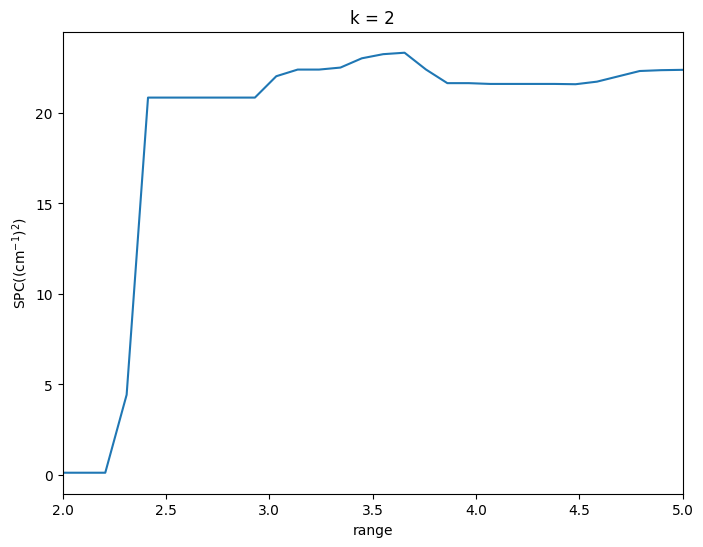

In [3]:
def density_spc_nmds(CFPs,mol,maxAA,nmds_list,filename):
    minAA = 2.0
    fig = plt.figure(figsize=(8, 6))
    x = np.linspace(minAA, maxAA, 30)
    y = np.zeros([30],dtype=float)
    Num = np.zeros([30],dtype=float)
    for k in range(0,30):
        AAk = x[k]
        print("Range:",AAk)
        origgr,newgr,atoms_label=choose_group('inpfile/eq_opt.xyz','Dy','./',AAk,0)
        Num[k] = newgr.get_number_of_atoms()
        CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
        CFPs.transB_sl(mol.massvecs)
        #CFPs.transB_sl(mol.vecs)
        Ba = 0#np.zeros([nmds],dtype=float)
        theta_2 = 1#-2/315
        #theta_4 = -8/135135
        #theta_6 = 4/3864861
        for i in nmds_list:
            for j in range(0,5):
                Ba += (CFPs.B_slope[i,j]/theta_2)**2
            # for j in range(5,14):
            #     Ba += (CFPs.B_slope[i,j]/theta_4)**2
            # for j in range(14,27):
            #     Ba += (CFPs.B_slope[i,j]/theta_6)**2
        y[k] = Ba
    plt.plot(x,y)
    plt.xlim(minAA,maxAA)
    #plt.ylim(-200,200)
    #plt.legend(loc=0,ncol=1)
    plt.title("k = {x}".format(x = 2)) 
    plt.xlabel("range") 
    plt.ylabel("SPC((cm$^{-1}$)$^{2}$)") 
    np.savetxt(filename+'.txt',y)
    plt.savefig(filename+'.png',bbox_inches='tight')
    plt.show()

#density_spc_nmds(CFPs,mol,5.0,[116,117,118],"SPC_nmds")
density_spc_nmds(TAU.CFPs,TAU.mol,5.0,TAU.Modes_list,"SPC_nmds")

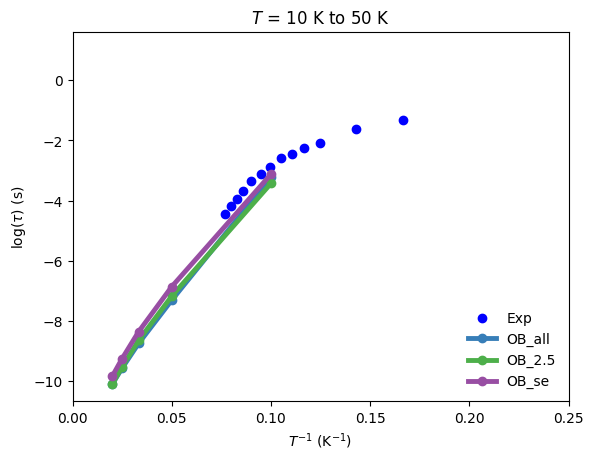

In [11]:
"""
If_Simplified: True
SimVP_filename: "inpfile/test2/VP_exp12_rt_mode_gs"
SimTPs_foldname: "TPs_test2/TP_exp12_rt_mode_sig10_gs"
nloop: 5
Simsigma: 10
"""
def read_RTfile(filename):
    ad = np.loadtxt(filename)
    RMTlist = ad[...,0]
    RMavg = ad[...,1]
    RMstd = ad[...,2]
    return RMTlist,RMavg,RMstd

figs1 = plt.figure(num='Figs1').add_subplot(111)

"""
Draw the data you pre-entered in .yml
"""

if If_Data:
    ndata = int(pinput['ndata'])
    for i in range(1,ndata+1):
        Tr = pinput['Tr{x}'.format(x = i)]
        logtime = pinput['logtime{x}'.format(x = i)]
        lb = pinput['label{x}'.format(x = i)]
        figs1.plot(Tr,logtime,"ob",label=lb)



filename = "TPs_file/OB_all.dat"
OBTlist,OBavg,OBstd = read_RTfile(filename)
draw_std_line('OB_all',1,-OBavg,OBstd,OBTlist,nloop)
filename = "TPs_file/OB_25.dat"
OBTlist,OBavg,OBstd = read_RTfile(filename)
draw_std_line('OB_2.5',2,-OBavg,OBstd,OBTlist,nloop)
filename = "TPs_file/OB_se.dat"
OBTlist,OBavg,OBstd = read_RTfile(filename)
draw_std_line('OB_se',3,-OBavg,OBstd,OBTlist,nloop)

# j = 277
# k = 276
# omega0 = 1257
# omega1 = mol.freqs[j]
# omega2 = mol.freqs[k]
# omega3 = mol.freqs[274]

# k0=const.hbar*2*np.pi*const.c*omega0/const.kb
# b0 = 11.83
# k1=const.hbar*2*np.pi*const.c*omega1/const.kb
# b1 = -2.69
# k2=const.hbar*2*np.pi*const.c*omega2/const.kb
# b2 = -2.55
# k3=const.hbar*2*np.pi*const.c*omega3/const.kb
# b3 = -3.45


# print(np.exp(k1*0.1))
# x = np.linspace(0,0.1,10)
# y1 = np.exp(-k1*x)*10**b1
# y2 = np.exp(-k2*x)*10**b2
# y3 = np.exp(-k3*x)*10**b3
# print(np.log(1/y1))
# figs1.plot(x,np.log10(1/y1),label=r"$\mathit{\alpha}$")
# figs1.plot(x,np.log10(1/y2),label=r"$\mathit{\beta}$")
# figs1.plot(x,np.log10(1/y3),label=r"$\mathit{\gamma}$")
# figs1.plot(x,np.log10(1/(y1+y2+y3)),label=r"$\mathit{\alpha}+\mathit{\beta}$")

Tmin = T_list[0]
Tmax = np.max(T_list)
figs1.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figs1.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
figs1.set_ylabel(r"log($\mathit{\tau}$) (s)") 
figs1.set_xlim(0,0.25)
#figs1.set_ylim(-4,6)
figs1.yaxis.set_major_locator(MultipleLocator(2))

#fig1.xaxis.set_major_locator(MultipleLocator(0.01))
#plt.xticks(1/T_list,T_list)



plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
plt.savefig("TPss1.eps",bbox_inches='tight')
plt.show()
#TP90_0.Mod_Analyse_OB(0)
#TP90_0.Mod_Analyse_RM(0)
#TP80_0.Mod_Analyse_OB(0)
#TP80_0_0.Mod_Analyse_OB(-1)
#TP80_0_0.Mod_Analyse_RM(-1)
#TP40_0_0.Mod_Analyse_RM(-1)
#TP10_0_0.Mod_Analyse_RM(-1)
#TP100_0.Mod_Analyse_OB(0)
#TP20_0.Mod_Analyse_RM(0)
#print(TP30_0.OBTP)
#print(TP30_0.OBrate)
#print(TP35_0.OBrate)
#print(TP30_0.OBrate)

#print(TP60_0.testS)
#print(TP60_0.U)
#print(TP60_0.Vh)

#print(TP40_0.testS)
#print(TP40_0.U)
#print(TP40_0.Vh)
#print(TP45_0.OBrate)

#print(TP100_0.OBrate)
#print(TP100_0.testS)
#print(TP45_0.OBrate)
#print(TP40_0.OBTP)
#TP100_3.Mod_Analyse_RM(3)
#TP100_0.Mod_Analyse_OB(0)
#TP30_0.Mod_Analyse_OB(0)
#TP20_0.Mod_Analyse_RM(0)
#TP25_0.Mod_Analyse_RM(0)
# TP80_2.Mod_Analyse_OB(1)
# TP70_2.Mod_Analyse_OB(1)
# TP60_2.Mod_Analyse_OB(1)

In [29]:
f = 1
i = 0
k = 276
j = 277
a = 0
omega1 = mol.freqs[j]
omega2 = mol.freqs[k]
#VP_filename = "inpfile/VP_exp_Cp_diag_mf.log"
VP_filename = "inpfile/test2/VP_exp12_rt_mode.log"
#VP_filename = "inpfile/VP_exp_CPmf_mode.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
table = PrettyTable(["i","V1","V2","dE+","dE-","s1","s2","a","da","a2"]) 
for c in range(0,Eigen.n_states):
    if Eigen.Vaules[c]<5000:
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
        s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
        a = a+da
        a2 = get_Mod_square(a)
        table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
                       '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
                        '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
                        '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
                        '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
                        '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
                        '%1.2e'%a2])
print(table)
"""
table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
    '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
    '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
    '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
    '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
    '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
    '%1.2e'%a2])
"""

yes
0.0 0.0 20.712868 38.761422
0.0 0.0 20.712868 38.761422
481.86100249 0.0 20.712868 38.761422
481.86100249 0.0 20.712868 38.761422
755.67250372 0.0 20.712868 38.761422
755.67250372 0.0 20.712868 38.761422
934.02605753 0.0 20.712868 38.761422
934.02605753 0.0 20.712868 38.761422
1094.99946264 0.0 20.712868 38.761422
1094.99946264 0.0 20.712868 38.761422
1247.45393569 0.0 20.712868 38.761422
1247.45393569 0.0 20.712868 38.761422
1366.83113592 0.0 20.712868 38.761422
1366.83113592 0.0 20.712868 38.761422
1446.56347659 0.0 20.712868 38.761422
1446.56347659 0.0 20.712868 38.761422
+----+--------------------+--------------------+----------+-----------+----------------------+----------------------+----------------------+----------------------------+----------+
| i  |         V1         |         V2         |   dE+    |    dE-    |          s1          |          s2          |          a           |             da             |    a2    |
+----+--------------------+--------------------+----

'\ntable.add_row([c,\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+\'j\',    \'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+\'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+\'j\',    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),    \'%1.2e\'%s1.real+","+\'%1.2e\'%s1.imag+\'j\',    \'%1.2e\'%s2.real+","+\'%1.2e\'%s2.imag+\'j\',    \'%1.2e\'%a.real+","+\'%1.2e\'%a.imag+\'j\',    \'%1.5e\'%da.real+","+\'%1.5e\'%da.imag+\'j\',    \'%1.2e\'%a2])\n'

In [28]:
f = 1
i = 0
k = 274
j = 275
a = 0
omega1 = mol.freqs[j]
omega2 = mol.freqs[k]
#VP_filename = "inpfile/VP_exp_Cp_diag_mf.log"
#VP_filename = "inpfile/test2/VP_exp12_rtp_xyz4.log"
VP_filename = "inpfile/VP_exp_CPmf_mode.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
table = PrettyTable(["i","V1","V2","dE+","dE-","s1","s2","a","da","a2"]) 
for c in range(0,Eigen.n_states):
    if Eigen.Vaules[c]<5000:
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
        s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
        a = a+da
        a2 = get_Mod_square(a)
        table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
                       '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
                        '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
                        '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
                        '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
                        '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
                        '%1.2e'%a2])
print(table)
"""
table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
    '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
    '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
    '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
    '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
    '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
    '%1.2e'%a2])
"""

yes
0.0 0.0 43.578574 52.13984
0.0 0.0 43.578574 52.13984
481.86100249 0.0 43.578574 52.13984
481.86100249 0.0 43.578574 52.13984
755.67250372 0.0 43.578574 52.13984
755.67250372 0.0 43.578574 52.13984
934.02605753 0.0 43.578574 52.13984
934.02605753 0.0 43.578574 52.13984
1094.99946264 0.0 43.578574 52.13984
1094.99946264 0.0 43.578574 52.13984
1247.45393569 0.0 43.578574 52.13984
1247.45393569 0.0 43.578574 52.13984
1366.83113592 0.0 43.578574 52.13984
1366.83113592 0.0 43.578574 52.13984
1446.56347659 0.0 43.578574 52.13984
1446.56347659 0.0 43.578574 52.13984
+----+--------------------+--------------------+----------+-----------+----------------------+----------------------+----------------------+----------------------------+----------+
| i  |         V1         |         V2         |   dE+    |    dE-    |          s1          |          s2          |          a           |             da             |    a2    |
+----+--------------------+--------------------+----------+---------

'\ntable.add_row([c,\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+\'j\',    \'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+\'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+\'j\',    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),    \'%1.2e\'%s1.real+","+\'%1.2e\'%s1.imag+\'j\',    \'%1.2e\'%s2.real+","+\'%1.2e\'%s2.imag+\'j\',    \'%1.2e\'%a.real+","+\'%1.2e\'%a.imag+\'j\',    \'%1.5e\'%da.real+","+\'%1.5e\'%da.imag+\'j\',    \'%1.2e\'%a2])\n'

yes


100%|██████████| 278/278 [00:26<00:00, 10.59it/s]

[-7.10059463 -7.72157679 -7.82939474 ... -7.77152713 -5.4286531
 -7.11658246]


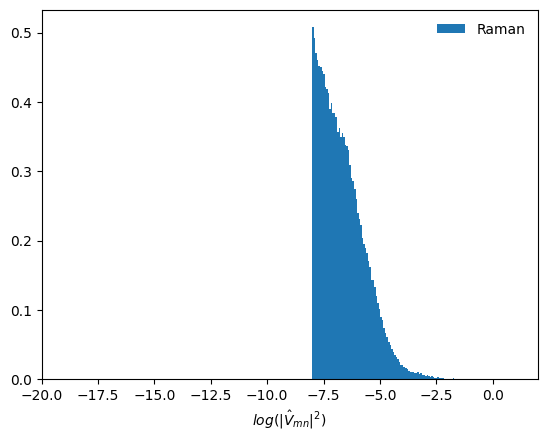

In [27]:
from tqdm import tqdm  
f = 2
i = 0
Vlist2 = np.empty((0,),dtype=float)
#VP_filename = "inpfile/VP_exp12_rt_xyz.log"
VP_filename = "inpfile/test2/VP_exp12_rt_per_gs1_0.log"
#VP_filename = "inpfile/VP_exp12_rt_mode3.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
for k in tqdm(range(0,CFPs.nmds)):
    for j in range(0,CFPs.nmds):
        omega1 = mol.freqs[j]
        omega2 = mol.freqs[k]
        for c in range(0,Eigen.n_states):
            a = 0
            if Eigen.Vaules[c]<5000:
                #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                #s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
                #s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
                #print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
                a = a+da
            a2 = get_Mod_square(a)
            #a2 = max(1e-10,a2)
            if a2 > 1e-8:
                Vlist2 = np.append(Vlist2,np.log10(a2))
print(Vlist2)
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist2, bins=100,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
figB.set_xlim(-20,2)
plt.show()


In [68]:
#print(TP90_0.OBVector)
TP = TP90_0.OBTP
eigenvalues,Vector = np.linalg.eig(TP)
eigen = np.zeros([16,16],dtype = float)
for i in range(0,16):
    eigen[i,i] = eigenvalues[i]
rate = -eigenvalues
rate,Vector = Sort_EV(rate,Vector)
#print(eigenvalues[1]*Vector[:,1])
Vector1 = np.linalg.inv(Vector)
#print(np.dot(eigen,Vector1)-np.dot(Vector1,TP))
#print(np.dot(TP,Vector))
print(-rate)
print(-rate[1])
i = 0
a = 0
for j in range(0,16):
    a += Vector1[1,j]*TP[j,i]
    print(a,j)
print(a,-rate[1]*Vector1[1,i])

np.savetxt("Vector1file",Vector1)

[-2.34061258e-04 -3.66671721e+02 -3.49638362e+07 -3.55092550e+07
 -4.47895992e+10 -4.50198948e+10 -6.46997666e+10 -6.47797759e+10
 -1.11191202e+11 -4.43610937e+11 -6.77773114e+12 -6.79782858e+12
 -8.05185150e+12 -8.06648324e+12 -1.28549501e+13 -1.31786940e+13]
-366.67172111485667
13804.204290958136 0
13804.204290958136 1
13804.204290958136 2
13804.204290958136 3
13804.204290958136 4
13804.204290958136 5
13804.20432556997 6
11191.052599938002 7
259.1387995220375 8
259.15665485054143 9
259.15665485054143 10
259.15665485054143 11
259.1566548505418 12
259.15665485045383 13
259.1554130598457 14
259.1577907403045 15
259.1577907403045 259.1579850620367


466.430822


100%|██████████| 10000/10000 [19:02<00:00,  8.75it/s]


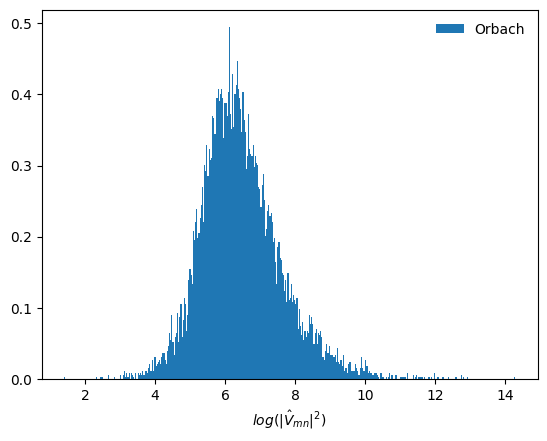

"k = 246\nj = 188\nomega1 = mol.freqs[j]\n#b1 = green_OB(omega_fi,omega1,sigma,T)  \nomega2 = mol.freqs[k]\nCFPs.read_CFPs()\nCFPs.gen_slope()\nfor ipt in range(0,number):\n    CFPs.random_CFPs_gs(10)     \n    a=0 \n    for c in range(0,Eigen.n_states):\n        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          \n        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) \n        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          \n        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) \n        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        a = a+da\n    a2 = get_Mod_square(a)\n    #print(a2)\n    Vlist3 = np.append(Vlist3,np.log10(a2))\n\nfigC = plt.figure(num='FigB').add_subplot(111)\nn,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')\nplt.legend(frameon=Fal

In [3]:
from tqdm import tqdm  

T = 80
f = 2
i = 0
mod1 = 202
mod2 = 203
number = 10000
Vlist1 = np.empty((0,),dtype=float)
Vlist2 = np.empty((0,),dtype=float)
Vlist3 = np.empty((0,),dtype=float)
Blist = np.empty((0,),dtype=float)
omega_fi = Eigen.Vaules[f]-Eigen.Vaules[i]
omega_fi2 = Eigen.Vaules[f]-Eigen.Vaules[i]
omega1 = mol.freqs[mod1]
print(omega1)
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[mod2]
#b2 = green_OB(omega_fi,omega2,sigma,T) 
#widgets = ["doing task: ", progressbar.Percentage()," ", progressbar.Bar(), " ", progressbar.ETA()]


#pbar = progressbar.ProgressBar(maxval=number, widgets=widgets).start()
#Eigen.Expansion(1)
#Eigen.Expansion(3)
#Eigen.Expansion(8)


for ipt in tqdm(range(0,number)):
    CFPs.random_CFPs_llz(1.70,3.09)
    VPfi1 = Eigen.s_ph(f,i,CFPs.B_slope[mod1,...])          
    a = get_Mod_square(VPfi1)
    b = green_OB(omega_fi,omega1,sigma,T)
    VPfi2 = Eigen.s_ph(f,i,CFPs.B_slope[mod2,...])          
    a2 = get_Mod_square(VPfi2)
    b2 = green_OB(omega_fi,omega2,sigma,T)
    #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
    #c = Rou_omega(abs(omega_if),omega1,sigma)
    TPtemp =2*np.pi**2*(a*b+a2*b2)*const.c*1e10*(1-Delta(f,i))
    #rate = 2*np.pi**2*(a1*b1+a2*b2)*const.c*1e10*(1-Delta(f,i))  
    #time = np.log10(1/rate)
    Vlist1 = np.append(Vlist1,np.log10(TPtemp))
    #Vlist2 = np.append(Vlist2,np.log10(a2))
    #Blist = np.append(Vlist1,np.log10(a1))

np.savetxt(Out_foldname+"/Vlist.dat",Vlist1)
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist1, bins=400,density=True,label='Orbach')
#n,bins,patchs=figB.hist(Vlist2, bins=400,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
# figB.set_xlim(-4,0)
plt.show()
"""k = 246
j = 188
omega1 = mol.freqs[j]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[k]
CFPs.read_CFPs()
CFPs.gen_slope()
for ipt in range(0,number):
    CFPs.random_CFPs_gs(10)     
    a=0 
    for c in range(0,Eigen.n_states):
        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          
        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) 
        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          
        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) 
        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        a = a+da
    a2 = get_Mod_square(a)
    #print(a2)
    Vlist3 = np.append(Vlist3,np.log10(a2))

figC = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
#figC.set_xlim(-4,0)
plt.show()"""


#np.log10(1/Rate)

#np.savetxt("Vectorfile",TP90_0.OBVector)

100%|██████████| 10/10 [00:29<00:00,  2.98s/it]


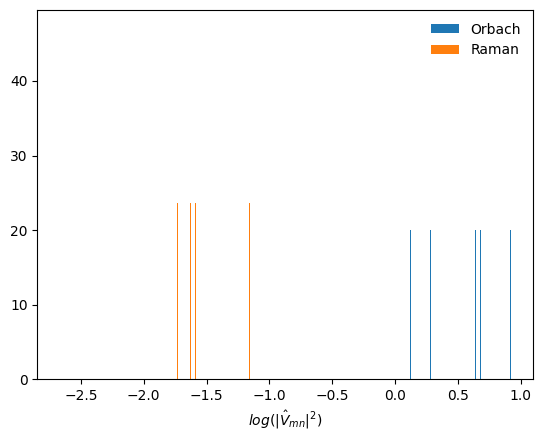

"k = 246\nj = 188\nomega1 = mol.freqs[j]\n#b1 = green_OB(omega_fi,omega1,sigma,T)  \nomega2 = mol.freqs[k]\nCFPs.read_CFPs()\nCFPs.gen_slope()\nfor ipt in range(0,number):\n    CFPs.random_CFPs_gs(10)     \n    a=0 \n    for c in range(0,Eigen.n_states):\n        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          \n        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) \n        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          \n        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) \n        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        a = a+da\n    a2 = get_Mod_square(a)\n    #print(a2)\n    Vlist3 = np.append(Vlist3,np.log10(a2))\n\nfigC = plt.figure(num='FigB').add_subplot(111)\nn,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')\nplt.legend(frameon=Fal

In [ ]:
from tqdm import tqdm  

T = 60
f1 = 2
f2 = 2
i = 0
mod1 = 245
mod2 = 188
number = 1000
Vlist1 = np.empty((0,),dtype=float)
Vlist2 = np.empty((0,),dtype=float)
Vlist3 = np.empty((0,),dtype=float)
Blist = np.empty((0,),dtype=float)
omega_fi1 = Eigen.Vaules[f1]-Eigen.Vaules[i]
omega_fi2 = Eigen.Vaules[f1]-Eigen.Vaules[i]
omega1 = mol.freqs[mod1]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[mod2]
#b2 = green_OB(omega_fi,omega2,sigma,T) 
#widgets = ["doing task: ", progressbar.Percentage()," ", progressbar.Bar(), " ", progressbar.ETA()]


#pbar = progressbar.ProgressBar(maxval=number, widgets=widgets).start()
#Eigen.Expansion(1)
#Eigen.Expansion(3)
#Eigen.Expansion(8)


for ipt in tqdm(range(0,number)):
    CFPs.random_CFPs_llz(llzA,llzw)
    VPfi1 = Eigen.s_ph(f1,i,CFPs.B_slope[mod1,...])          
    a1 = get_Mod_square(VPfi1)
    """VPfi2 = Eigen.s_ph(f2,i,CFPs.B_slope[mod2,...])  
    a1 = get_Mod_square(VPfi1)"""
    a = 0
    for c in range(0,Eigen.n_states):
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        VP1 = Eigen.s_ph(f2,c,CFPs.B_slope[mod1,...])
        VP2 = Eigen.s_ph(c,i,CFPs.B_slope[mod2,...])
        VP3 = Eigen.s_ph(f2,c,CFPs.B_slope[mod2,...])
        VP4 = Eigen.s_ph(c,i,CFPs.B_slope[mod1,...])
        da = VP1*VP2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+VP3*VP4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        a = a+da
    a2 = get_Mod_square(a)
    #rate = 2*np.pi**2*(a1*b1+a2*b2)*const.c*1e10*(1-Delta(f,i))  
    #time = np.log10(1/rate)
    Vlist1 = np.append(Vlist1,np.log10(a1))
    Vlist2 = np.append(Vlist2,np.log10(a2))
    #Blist = np.append(Vlist1,np.log10(a1))


figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist1, bins=400,density=True,label='Orbach')
n,bins,patchs=figB.hist(Vlist2, bins=400,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
# figB.set_xlim(-4,0)
plt.show()
"""k = 246
j = 188
omega1 = mol.freqs[j]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[k]
CFPs.read_CFPs()
CFPs.gen_slope()
for ipt in range(0,number):
    CFPs.random_CFPs_gs(10)     
    a=0 
    for c in range(0,Eigen.n_states):
        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          
        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) 
        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          
        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) 
        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        a = a+da
    a2 = get_Mod_square(a)
    #print(a2)
    Vlist3 = np.append(Vlist3,np.log10(a2))

figC = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
#figC.set_xlim(-4,0)
plt.show()"""


#np.log10(1/Rate)

7506
(401,)
(400,)
[-592.10787511 -588.69160792 -585.27534073 -581.85907354 -578.44280635
 -575.02653916 -571.61027197 -568.19400478 -564.77773759 -561.3614704
 -557.94520321 -554.52893602 -551.11266883 -547.69640165 -544.28013446
 -540.86386727 -537.44760008 -534.03133289 -530.6150657  -527.19879851
 -523.78253132 -520.36626413 -516.94999694 -513.53372975 -510.11746256
 -506.70119537 -503.28492818 -499.868661   -496.45239381 -493.03612662
 -489.61985943 -486.20359224 -482.78732505 -479.37105786 -475.95479067
 -472.53852348 -469.12225629 -465.7059891  -462.28972191 -458.87345472
 -455.45718753 -452.04092035 -448.62465316 -445.20838597 -441.79211878
 -438.37585159 -434.9595844  -431.54331721 -428.12705002 -424.71078283
 -421.29451564 -417.87824845 -414.46198126 -411.04571407 -407.62944688
 -404.2131797  -400.79691251 -397.38064532 -393.96437813 -390.54811094
 -387.13184375 -383.71557656 -380.29930937 -376.88304218 -373.46677499
 -370.0505078  -366.63424061 -363.21797342 -359.80170623 -3

c:\Users\10122\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


0.8472813257242207 65.44833208074904


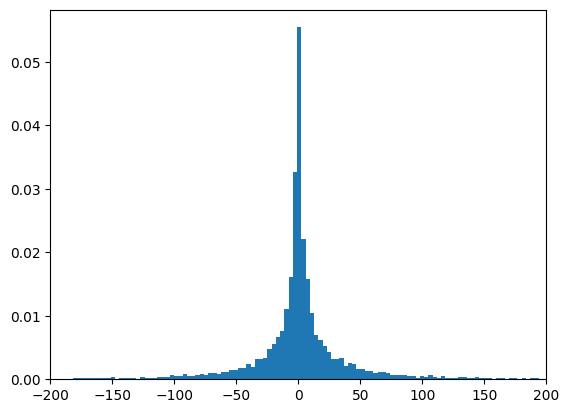

KstestResult(statistic=0.37534346447589884, pvalue=0.0, statistic_location=2.155948952846863, statistic_sign=-1)


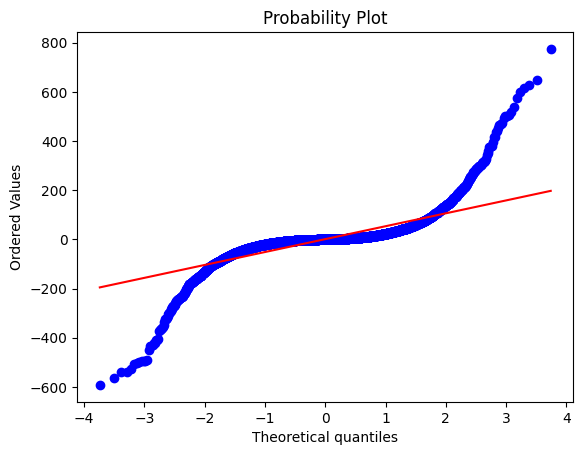

In [14]:
from scipy import stats
CFPs.read_CFPs()
B = CFPs.Line_CFPs()
np.savetxt(Out_foldname+"/Btheta.dat",B)
print(B.size)
B_new = []
A_new = []
lim = 200
A = []
# A = np.random.normal(0,1,9000)
# A2 = np.random.normal(0,5,6000)
# A3 = np.random.normal(0,10,3000)
# A4 = np.random.uniform(-200,200,3000)
# A = np.append(A,A2)
# A = np.append(A,A3)
# A = np.append(A,A4)
# for k in range(0,10000):
#     num = np.random.randint(1,8)
#     if num <= 3:
#         A.append(np.random.normal(loc=0.0, scale=1))
#     if num > 3 and num <= 5:
#         A.append(np.random.normal(loc=0.0, scale=5))
#     if num == 6:
#         A.append(np.random.normal(loc=0.0, scale=10))
#     if num == 7:
#         A.append(np.random.random()*400-200)
for i in range(0,np.shape(B)[0]):
    if B[i] <= lim and B[i] >= -lim:
        B_new.append(10*B[i])
# for i in range(0,np.shape(A)[0]):
#     if A[i] <= lim and A[i] >= -lim:
#         A_new.append(A[i])
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(B_new, bins=400,density=True)
print(np.shape(bins))
print(np.shape(n))
print(bins)
#np.savetxt(Out_foldname+"/distri.dat",np.column_stack((bins,n)))
n,bins,patchs=figB.hist(A_new, bins=400,density=True)
figB.set_xlim(-lim,lim)
#figB.set_ylim(0,0.05)
#B = [-1,0,1]
#B = np.random.normal(0,10,1000)
avg=np.mean(B_new)
std=np.std(B_new)
print(avg,std)
# avg=np.mean(A_new)
# std=np.std(A_new)
# print(avg,std)
plt.savefig("PB_acac.png",bbox_inches='tight')
plt.show()



#A = np.random.normal(0,10,1000)
B = np.sort(B_new)
stats.probplot(B_new,dist="norm",plot=plt)
plt.savefig("QQ_acac.png",bbox_inches='tight')
p = stats.kstest(B_new,"norm")
print(p)


T = 80K
2.26e+01 2.26e+01 2.35e+03 0.0047984446193518725
T = 90K
3.67e+02 3.67e+02 1.95e+04 0.009391186829806478
T = 100K
3.47e+03 3.46e+03 1.07e+05 0.01614055747991533


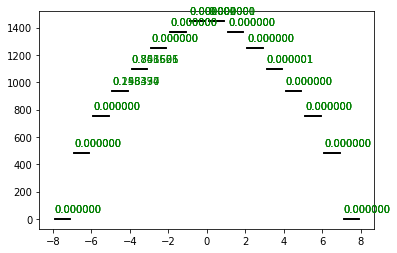

In [29]:
for T in T_list:
    if T < 50:
        continue
    else:
        T = int(T)
        name = 'TP{x}_{y}'.format(x=T,y=0)
        print("T = {x}K".format(x=T))
        P_states = np.zeros([16],dtype = float)
        P_states_temp = np.zeros([16],dtype = float)
        OBTP = locals()[name].OBTP
        OBTPP = locals()[name].OBTPP
        OBrate = locals()[name].OBrate
        for i in range(1,16):
            P_states[i] = -OBTP[i,0]/OBTP[0,0]
        for i in range(0,16):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        for i in range(0,16):  
            plt.text(Eigen.JAN[i]-0.4, Eigen.Vaules[i]+50, '%1.6f'%P_states[i], fontsize=10, color='green')
        # figOBT = plt.figure(num='FigOBT').add_subplot(111)
        # figOBT.set_title("Transition probability for Orbach at {T}K".format(T = T)) 
        # figOBT.set_xlabel("<J$_Z$>") 
        # figOBT.set_ylabel("Energy(cm$^{-1}$)") 
        # plt.show()
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([16],dtype = float)
            for i in range(0,16):
                for j in range(2,16):
                    P_states_temp[i] += OBTPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print(P_states)

            # figOBT = plt.figure(num='FigOBT').add_subplot(111)
            # figOBT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
            # CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
            # cl = CL_fmt[0]
            # for i in range(0,16):
            #     x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            #     y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            #     plt.plot(x,y,color='k')
            # for i in range(0,16):  
            #     plt.text(Eigen.JAN[i]-0.4, Eigen.Vaules[i]+50, '%1.8f'%P_states[i], fontsize=10, color='green')
            # figOBT.set_title("Transition probability for Orbach at {T}K".format(T = T)) 
            # figOBT.set_xlabel("<J$_Z$>") 
            # figOBT.set_ylabel("Energy(cm$^{-1}$)") 
            # plt.show()
            if P_states[0]+P_states[1]>0.99999999:
                print('%1.2e'%(-OBTP[0,0]*P_states[1]*2),'%1.2e'%OBrate[1], '%1.2e'%(-OBTP[0,0]),P_states[1])
                #print('%1.2e'%(-OBTP[0,0]),P_states[1])
                break

RM
T = 80K
2.63e+04 2.63e+04 2.84e+06 0.004628163038853553
T = 90K
3.73e+05 3.73e+05 1.05e+07 0.017728922033295746
T = 100K
2.84e+06 2.84e+06 3.34e+07 0.04260434362625983
OB
T = 80K
2.26e+01 2.26e+01 2.35e+03 0.0047984446193518725
T = 90K
3.67e+02 3.67e+02 1.95e+04 0.009391186829806478
T = 100K
3.47e+03 3.46e+03 1.07e+05 0.01614055747991533

In [37]:
from numpy.random import RandomState
rng = RandomState(123456)

num_v = 4

weights = rng.uniform(0, 1, num_v * num_v).reshape((num_v, num_v))
weights = np.tril(weights) + np.triu(weights.T, 1)
np.fill_diagonal(weights, 0)

degrees = weights.sum(axis=0)

degrees_rw = 1 / degrees
D_rw = np.diag(degrees_rw)

degrees = 1 / np.sqrt(degrees)
D = np.diag(degrees)

I = np.eye(num_v)

laplacian = I - np.matmul(np.dot(D, weights), D)

eigenvalues,Vector = eig(laplacian)
rate = -eigenvalues
rate,Vector = Sort_EV(rate,Vector)
U,S,Vh= np.linalg.svd(laplacian, full_matrices=True, compute_uv=True)
print(-rate)
print(S)

[1.57642803+0.j 1.40644541+0.j 1.01712657+0.j 0.        +0.j]
[1.57642803e+00 1.40644541e+00 1.01712657e+00 1.73174256e-16]


C:\Users\10122\AppData\Local\Temp\ipykernel_32232\1588556788.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)


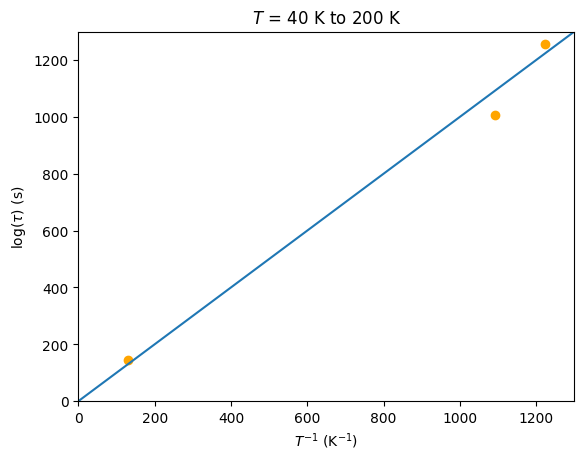

In [112]:
Expf = [129.9,1223,1093]
Full = [143.4,1257,1006]
Exps = []
Sim = []
x = [0, 1300]
y = [0, 1300]
fig3 = plt.figure(num='Fig3').add_subplot(111)
plt.figure("Fig3")
plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
plt.plot(x, y)
plt.scatter(Expf, Full, c='orange', label='Full')
fig3.set_xlim(0,1300)
fig3.set_ylim(0,1300)
fig3.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
fig3.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
fig3.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.show()


[4.01012006]


C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27010 (\N{CJK UNIFIED IDEOGRAPH-6982}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23494 (\N{CJK UNIFIED IDEOGRAPH-5BC6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py

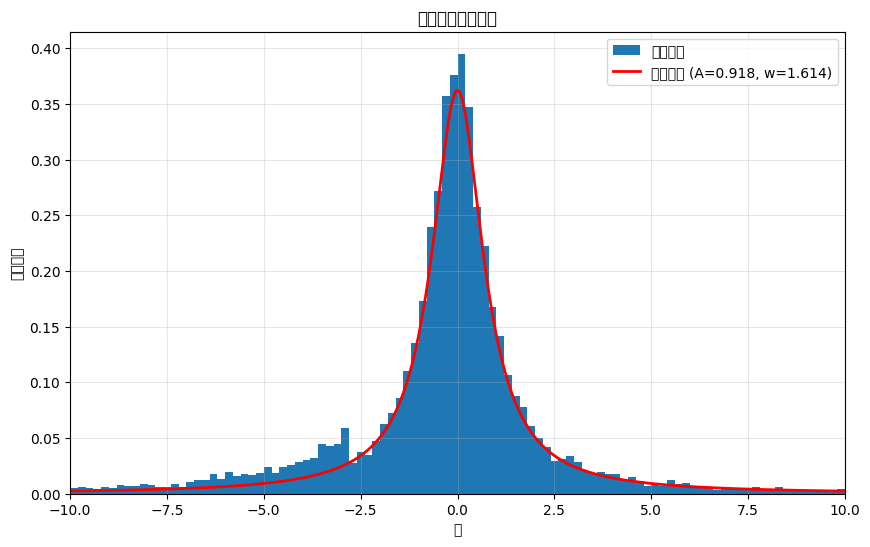

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def generate_custom_lorentz(A, w, size=1):
    """
    生成符合指定洛伦兹分布的随机数
    分布公式：y = (2*A/pi)*(w/(4*x^2 + w^2))
    
    参数:
        A: 振幅参数
        w: 宽度参数
        size: 生成的随机数数量，默认值为1
        
    返回:
        符合指定洛伦兹分布的随机数数组
    """
    # 生成[0, 1)区间的均匀分布随机数
    uniform_rvs = np.random.uniform(0, 1, size)
    
    # 根据逆变换法，从指定的洛伦兹分布生成随机数
    # 推导过程：通过对分布函数求逆得到此转换公式
    lorentz_rvs = (w / 2) * np.tan(np.pi * (uniform_rvs/A - 1/2))
    
    return lorentz_rvs

# 示例用法
if __name__ == "__main__":
    # 设置参数
    A = 0.918         # 振幅参数
    w = 1.614         # 宽度参数
    sample_size = 10000  # 样本数量
    print(generate_custom_lorentz(A=A, w=w))
    
    # 生成随机数
    lorentz_samples = generate_custom_lorentz(A=A, w=w, size=sample_size)
    
    # 绘制直方图以可视化分布
    plt.figure(figsize=(10, 6))
    plt.hist(lorentz_samples, bins=100,range=(-10,10), density=True, label='采样结果')
    
    # 绘制理论概率密度函数进行对比
    x = np.linspace(-10, 10, 1000)
    y = (2 * A / np.pi) * (w / (4 * x**2 + w**2))  # 指定的分布公式
    plt.plot(x, y, 'r-', lw=2, label=f'理论分布 (A={A}, w={w})')
    
    plt.title('自定义洛伦兹分布')
    plt.xlabel('值')
    plt.ylabel('概率密度')
    plt.xlim(-10, 10)  # 限制x轴范围以便更好地观察
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    